# EDA del scrap de la línea Xocoleta

Análisis exploratorio de los nueve CSV originales. El objetivo es cuantificar el desperdicio,
localizar patrones persistentes e incidencias y entregar una base para decidir qué anticipar
con machine learning y qué vigilar mediante indicadores del proceso.

## Cómo utilizar el notebook

Ejecutar todas las celdas en orden desde un kernel Python con `pandas`, `numpy`, `matplotlib`
e `IPython`. 

## Contenido

1. [Objetivo, alcance y comprensión](#1-objetivo-alcance-y-comprensión)
2. [Calidad, coherencia y preparación](#2-calidad-coherencia-y-preparación)
3. [Magnitud e impacto económico](#3-magnitud-e-impacto-económico)
4. [Distribución, persistencia e incidencias](#4-distribución-persistencia-e-incidencias)
5. [Relaciones con el proceso](#5-relaciones-con-el-proceso)
6. [Viabilidad de anticipación](#6-viabilidad-de-anticipación)
7. [Conclusiones y oportunidades](#7-conclusiones-y-oportunidades)


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import re
import sqlite3
import sys
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'data/fct_scrap_minute.csv').exists() and (p/'schema/xocoleta.sql').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Ejecutar desde la carpeta del proyecto o una subcarpeta.')
DATA = ROOT/'data'
OUT = ROOT/'analysis/eda_scrap'
EXPORT_RESULTS = True
FORECAST_HORIZON_MIN = 10
LOOKBACK_MIN = 20
EVENT_BUFFER_BEFORE_MIN = 5
EVENT_BUFFER_AFTER_MIN = 20
CORE_TO_BAR_LAG_MIN = 2
TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
HIGH_SCRAP_QUANTILE = 0.90
SEED = 42
np.random.seed(SEED)
if EXPORT_RESULTS:
    (OUT/'figures').mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_rows', 20)
pd.set_option('display.max_colwidth', 85)
plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 110,
                     'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'axes.axisbelow': True})
COLORS = ['#8b4a32', '#247b91', '#d88a35', '#727e4a']
POINT_COLORS={'FIN_BAR':COLORS[0],'POST_CAM':COLORS[1],'GUI_CHUTE':COLORS[2],'MLD_DUMP':COLORS[3]}
checks = []
def check(name, condition, detail='', fatal=False):
    checks.append({'comprobación': name, 'cumple': bool(condition), 'detalle': str(detail)})
    if fatal and not condition:
        raise AssertionError(f'{name}: {detail}')
def show(frame, n=15):
    preview=frame.head(n).copy()
    numeric=preview.select_dtypes(include='number').columns
    preview[numeric]=preview[numeric].round(5)
    display(preview)
def explain(text):
    display(Markdown(text))
def figure(fig, name):
    if EXPORT_RESULTS:
        fig.savefig(OUT/'figures'/f'{name}.png', dpi=150, bbox_inches='tight', facecolor='white')
    display(fig)
    plt.close(fig)
def export_table(frame, name, index=True):
    if EXPORT_RESULTS:
        frame.to_csv(OUT/f'{name}.csv', index=index, encoding='utf-8-sig')
def ratio(num, den):
    return num / den.replace(0, np.nan)
def fingerprint(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(2**20), b''):
            h.update(chunk)
    return h.hexdigest()
versions = {'python': platform.python_version(), 'pandas': pd.__version__,
            'numpy': np.__version__, 'matplotlib': matplotlib.__version__}
display(pd.Series(versions, name='Versión'))


python        3.12.14
pandas          3.0.1
numpy           2.5.4
matplotlib     3.11.2
Name: Versión, dtype: str

<a id="1-objetivo-alcance-y-comprensión"></a>

## 1. Objetivo, alcance y comprensión

Preguntas: ¿qué desperdicio tiene mayor coste?, ¿es habitual o aparece en episodios?,
¿dónde surge la desviación?, ¿qué señales existen antes de detectarla y con qué margen?

**Unidad física y temporal:** una lectura de sensor es un parámetro/minuto, un láser resume
un carril/minuto y una fila de scrap corresponde a un punto/minuto. Las cámaras registran
eventos, no todas las piezas. El lote de masa no permite seguir una barrita entre estaciones.
Las ventanas de línea son grupos temporales, no cohortes individuales trazadas.

Fuentes: `data/*.csv`, `schema/xocoleta.sql`, `README.txt` y `xocoleta-line.html`.
Los catálogos del SQL aportan unidades, límites, mecanismos y tarifas. El HTML explica el
desequilibrio transversal de la cortina y el desfase aproximado de dos minutos entre láseres.
El esquema se lee como metadatos en una base SQLite en memoria, sin cargar ni modificar los CSV.


In [2]:
schema_text = (ROOT/'schema/xocoleta.sql').read_text(encoding='utf-8')
html_text = (ROOT/'xocoleta-line.html').read_text(encoding='utf-8')
create_statements = dict(re.findall(r'CREATE TABLE (\w+) \((.*?)\);', schema_text, re.S))
conn = sqlite3.connect(':memory:')
for name, body in create_statements.items():
    if name.startswith('dim_'):
        conn.execute(f'CREATE TABLE {name} ({body})')
for statement in re.findall(r'INSERT INTO dim_\w+.*?;', schema_text, re.S):
    conn.execute(statement)
dims = {name: pd.read_sql_query(f'SELECT * FROM {name}', conn)
        for name in create_statements if name.startswith('dim_')}
conn.close()
machine = dims['dim_machine'].sort_values('sequence_no')
parameter = dims['dim_parameter']
specs = dims['dim_spec']
scrap_points = dims['dim_scrap_point'].set_index('collection_point_code')
primary_keys = {}
dictionary_rows = []
for name, body in create_statements.items():
    match = re.search(r'PRIMARY KEY \((.*?)\)', body)
    primary_keys[name] = [v.strip() for v in match.group(1).split(',')] if match else []
    for line in body.strip().splitlines():
        parts = line.strip().rstrip(',').split()
        if len(parts) >= 2 and parts[0] != 'PRIMARY':
            dictionary_rows.append({'tabla': name, 'variable': parts[0], 'tipo_sql': parts[1],
                                    'clave': parts[0] in primary_keys[name]})
dictionary = pd.DataFrame(dictionary_rows)
grain = {
 'fct_production_minute':'minuto de línea',
 'fct_telemetry_minute':'parámetro y minuto',
 'fct_vision_gap':'evento de hueco', 'fct_vision_crack':'evento de grieta',
 'fct_laser_core_minute':'carril y minuto, núcleo',
 'fct_laser_bar_minute':'carril y minuto, barrita',
 'fct_oee_minute':'activo y minuto; comprobar activos presentes',
 'fct_problem_event':'episodio registrado de problema',
 'fct_scrap_minute':'punto de recogida y minuto'}
time_columns = {'fct_vision_gap':['detected_at'], 'fct_vision_crack':['detected_at'],
                'fct_problem_event':['started_at', 'ended_at']}
tables, inventory_rows = {}, []
category_columns = {'machine_code','parameter_code','shift_code','sku_code','camera_code',
                    'severity','orientation','collection_point_code','scrap_type',
                    'state_code','problem_code','loss_type','oee_factor','dough_batch_id'}
started = time.perf_counter()
for path in sorted(DATA.glob('fct_*.csv')):
    name = path.stem
    dates = time_columns.get(name, ['minute_ts'])
    columns = pd.read_csv(path, nrows=0).columns
    dtypes = {c:'category' for c in columns if c in category_columns}
    dtypes.update({c:'int32' for c in columns if c in {'lane_no','pieces','length_oos','width_oos','height_oos'}})
    df = pd.read_csv(path, parse_dates=dates, dtype=dtypes)
    tables[name] = df
    inventory_rows.append({'tabla': name, 'filas':len(df), 'columnas':len(df.columns),
                           'granularidad':grain[name], 'desde':df[dates[0]].min(),
                           'hasta':df[dates[0]].max(),
                           'memoria_MB':df.memory_usage(deep=True).sum()/2**20,
                           'sha256':fingerprint(path)})
inventory = pd.DataFrame(inventory_rows).set_index('tabla')
check('Están los nueve CSV esperados', set(tables)==set(grain), fatal=True)
show(inventory.drop(columns='sha256'), 9)
print(f'Carga completa: {time.perf_counter()-started:.1f} s.')
show(machine, 15)
show(specs)


,filas,columnas,granularidad,desde,hasta,memoria_MB
tabla,,,,,,
fct_laser_bar_minute,2059200,12,"carril y minuto, barrita",2026-07-06 06:00:00,2026-10-02 22:29:00,149.24939
fct_laser_core_minute,2059200,12,"carril y minuto, núcleo",2026-07-06 06:00:00,2026-10-02 22:29:00,149.24939
fct_oee_minute,64350,14,activo y minuto; comprobar activos presentes,2026-07-06 06:00:00,2026-10-02 22:29:00,5.15794
fct_problem_event,398,9,episodio registrado de problema,2026-07-06 07:38:00,2026-10-02 19:05:00,0.04215
fct_production_minute,64350,5,minuto de línea,2026-07-06 06:00:00,2026-10-02 22:29:00,1.41971
fct_scrap_minute,57788,7,punto de recogida y minuto,2026-07-06 06:16:00,2026-10-02 22:29:00,2.31556
fct_telemetry_minute,3281850,5,parámetro y minuto,2026-07-06 06:00:00,2026-10-02 22:29:00,81.38134
fct_vision_crack,13971,7,evento de grieta,2026-07-06 06:16:39,2026-10-02 22:29:54,0.41370
fct_vision_gap,21217,8,evento de hueco,2026-07-06 06:15:15,2026-10-02 22:29:37,0.93126


Carga completa: 7.8 s.


,machine_code,machine_name,sequence_no,asset_type
0,MIX,Dough mixer,1,process
1,DST,Dough distributor,2,process
2,MLD,Moulder,3,process
3,CAM_PRE,"Camera, before the oven",4,camera
4,OVN,Oven,5,process
5,BCL,Biscuit cooler,6,process
6,CAM_POST,"Camera, after the oven",7,camera
7,BCM,Barrier cream,8,process
8,BCR,Barrier cooler,9,process
9,CAR,Caramel roller,10,process


,product_stage,measure_name,nominal_mm,lsl_mm,usl_mm
0,core,length,100.0,98.5,101.5
1,core,width,30.0,29.0,31.0
2,core,height,14.0,13.0,15.0
3,bar,length,103.0,101.0,105.0
4,bar,width,34.0,32.5,35.5
5,bar,height,18.0,16.6,19.4


### Diccionario y disponibilidad de variables

`value_actual` es la medida y `value_setpoint` la consigna. Los rangos del catálogo son
referencias del proceso: salir de ellos es una señal, no un motivo para borrar la fila.
`_avg` y `_sd` son media y desviación de las medidas; `_oos` cuenta piezas fuera de especificación.
Un mismo producto puede incumplir varias dimensiones. `cost_usd` es coste de material de scrap,
no facturación perdida ni margen comercial. En `MLD_DUMP`, `piece_count` cuenta cargas de masa,
no barritas. No se sumará como si tuviera la misma unidad que los otros puntos.


In [3]:
definitions = {
 'minute_ts':'Minuto observado en la estación; no identifica una pieza.',
 'detected_at':'Instante de detección de un evento de cámara.',
 'started_at':'Inicio del episodio registrado.', 'ended_at':'Fin del episodio, tratado como exclusivo.',
 'dough_batch_id':'Lote presente en moldeado; no es una clave individual de barrita.',
 'value_actual':'Lectura real; unidad y semántica en dim_parameter.',
 'value_setpoint':'Consigna configurada; no es una medida del producto.',
 'parameter_code':'Parámetro asociado a una máquina y una unidad.',
 'machine_code':'Activo o estación; LINE representa la línea.',
 'lane_no':'Carril paralelo, de 1 a 32.', 'pieces':'Piezas que alcanzaron ese láser en ese minuto.',
 'piece_count':'Piezas retiradas; en MLD_DUMP representa cargas, no barritas.',
 'quantity_kg':'Masa retirada en ese punto.', 'cost_usd':'Coste material de la retirada.',
 'usd_per_kg':'Tarifa material por kilogramo en el punto.',
 'collection_point_code':'Punto de retirada física, no necesariamente origen de la causa.',
 'good_bars':'Conteo de unidades buenas según el modelo OEE.',
 'reject_bars':'Conteo de rechazadas según OEE; no sumar al registro físico de scrap.',
 'total_bars':'Conteo de producción del modelo OEE.',
 'problem_code':'Problema registrado; presencia parcial, no causa única demostrada.',
 'note':'Texto del episodio; no asumir disponible antes de su registro.',
 'shift_code':'A, B o CLEAN según el calendario observado.',
 'line_speed_m_min':'Velocidad de línea en metros/minuto.'}
definitions.update({
 'sku_code':'Referencia de producto; revisar diversidad antes de comparar recetas.',
 'gap_event_id':'Identificador único del evento de hueco, no de una barrita.',
 'crack_event_id':'Identificador único del evento de grieta, no de una barrita.',
 'problem_event_id':'Identificador único del episodio registrado.',
 'camera_code':'Cámara que detecta el evento, previa o posterior al horno.',
 'gap_length_mm':'Extensión longitudinal de masa ausente.',
 'gap_width_mm':'Anchura afectada por el hueco.',
 'coverage_pct':'Porcentaje de la zona que conserva masa.',
 'crack_length_mm':'Longitud detectada de la grieta.',
 'orientation':'Orientación de la grieta según la cámara.',
 'severity':'Gravedad categórica registrada en el evento.',
 'state_code':'Estado dominante de línea según el registro OEE.',
 'scheduled_s':'Segundos del minuto dentro del calendario planificado.',
 'planned_downtime_s':'Segundos de parada prevista excluidos de tiempo de producción OEE.',
 'breakdown_s':'Segundos de parada no programada según el modelo OEE.',
 'minor_stop_s':'Segundos de microparada; comprobar convención de OEE antes de agregarlos.',
 'runtime_s':'Tiempo de funcionamiento según la definición de OEE del caso.',
 'ideal_bars_per_min':'Capacidad ideal de referencia por minuto.',
 'duration_s':'Duración declarada del episodio; se contrasta con inicio y fin.',
 'loss_type':'Tipo de pérdida registrado, como avería o velocidad reducida.',
 'oee_factor':'Factor al que el caso asigna la pérdida; no es un diagnóstico causal.',
 'scrap_type':'Tipo de material retirado en ese punto.'})
dictionary['significado'] = dictionary.variable.map(definitions)
for suffix, meaning in [('_avg','Media de la dimensión medida, mm.'),
                         ('_sd','Desviación estándar de la dimensión, mm.'),
                         ('_oos','Conteo fuera de especificación de esa dimensión.')]:
    dictionary.loc[dictionary.variable.str.endswith(suffix), 'significado'] = meaning
dictionary['significado'] = dictionary.significado.fillna('Consultar el nombre de campo y el catálogo SQL correspondiente.')
units={'minute_ts':'fecha/hora sin zona explícita','detected_at':'fecha/hora sin zona explícita',
       'started_at':'fecha/hora sin zona explícita','ended_at':'fecha/hora sin zona explícita',
       'value_actual':'dim_parameter.unit','value_setpoint':'dim_parameter.unit',
       'line_speed_m_min':'m/min','quantity_kg':'kg','cost_usd':'USD','usd_per_kg':'USD/kg',
       'pieces':'piezas medidas','piece_count':'piezas o cargas según punto',
       'total_bars':'barritas','good_bars':'barritas','reject_bars':'barritas',
       'ideal_bars_per_min':'barritas/min','coverage_pct':'%',
       'duration_s':'s','scheduled_s':'s','planned_downtime_s':'s','breakdown_s':'s',
       'minor_stop_s':'s','runtime_s':'s'}
dictionary['unidad']=dictionary.variable.map(units).fillna('identificador / categoría / metadato')
dictionary.loc[dictionary.variable.str.contains('_mm'), 'unidad']='mm'
dictionary.loc[dictionary.variable.str.endswith('_oos'), 'unidad']='piezas fuera de especificación'
show(dictionary[dictionary.tabla.str.startswith('fct_')], 18)
show(parameter[['parameter_code','machine_code','unit','setpoint','range_min','range_max','driver_note']], 12)
export_table(dictionary, 'diccionario_datos', index=False)
export_table(parameter, 'catalogo_parametros', index=False)
export_table(inventory, 'inventario_fuentes')


,tabla,variable,tipo_sql,clave,significado,unidad
32,fct_production_minute,minute_ts,TIMESTAMP,True,Minuto observado en la estación; no identifica una pieza.,fecha/hora sin zona explícita
33,fct_production_minute,dough_batch_id,VARCHAR,False,Lote presente en moldeado; no es una clave individual de barrita.,identificador / categoría / metadato
34,fct_production_minute,shift_code,VARCHAR,False,"A, B o CLEAN según el calendario observado.",identificador / categoría / metadato
35,fct_production_minute,sku_code,VARCHAR,False,Referencia de producto; revisar diversidad antes de comparar recetas.,identificador / categoría / metadato
36,fct_production_minute,line_speed_m_min,DOUBLE,False,Velocidad de línea en metros/minuto.,m/min
37,fct_telemetry_minute,minute_ts,TIMESTAMP,True,Minuto observado en la estación; no identifica una pieza.,fecha/hora sin zona explícita
38,fct_telemetry_minute,machine_code,VARCHAR,False,Activo o estación; LINE representa la línea.,identificador / categoría / metadato
39,fct_telemetry_minute,parameter_code,VARCHAR,True,Parámetro asociado a una máquina y una unidad.,identificador / categoría / metadato
40,fct_telemetry_minute,value_actual,DOUBLE,False,Lectura real; unidad y semántica en dim_parameter.,dim_parameter.unit
41,fct_telemetry_minute,value_setpoint,DOUBLE,False,Consigna configurada; no es una medida del producto.,dim_parameter.unit


,parameter_code,machine_code,unit,setpoint,range_min,range_max,driver_note
0,MIX_MOISTURE_PCT,MIX,%,18.5,16.4,20.2,Dry dough is the main path to cracks after the oven. Below about 17.6% the biscui...
1,MIX_SPECIFIC_ENERGY_KJ_KG,MIX,kJ/kg,14.0,8.0,22.0,Energy delivered into the batch through the agitator. High energy with low moistu...
2,MIX_SPEED_RPM,MIX,rpm,42.0,0.0,55.0,Zero while the agitator is stopped. A trip on torque drops this to zero mid-batch.
3,MIX_TORQUE_NM,MIX,N·m,180.0,40.0,320.0,Instantaneous torque. Specific energy is the integral of torque and speed over th...
4,MIX_DOUGH_TEMP_C,MIX,°C,24.0,18.0,32.0,Use with oven zone 1. A large gap between dough temperature and zone 1 is a therm...
5,DST_HOPPER_LEVEL_PCT,DST,%,62.0,0.0,100.0,The buffer between the mixer and the rest of the line. Gaps follow a low level on...
6,DST_MASS_FLOW_KG_MIN,DST,kg/min,28.0,0.0,34.0,Dough delivered toward the moulder. Falls with hopper level and with a blocked au...
7,DST_FEED_PRESSURE_BAR,DST,bar,1.8,0.4,2.6,Low pressure leaves the outer lanes short. The gap count rises across several lan...
8,DST_AUGER_RPM,DST,rpm,35.0,0.0,48.0,Zero during a bridge or a trip.
9,DST_DOUGH_TEMP_C,DST,°C,24.0,18.0,32.0,"Should track the mixer batch that is currently in the hopper, about 8 minutes later."


**Lectura del proceso:** mezcla → distribución → moldeado → cámara previa → horno → enfriado
→ cámara posterior → crema → enfriado → caramelo → guillotina → láser del núcleo → chocolate
→ láser final → enfriado final. El lugar donde se retira producto puede estar después de la
estación que originó el problema. Por ello no se etiquetará automáticamente el punto de scrap
como máquina causante.

<a id="2-calidad-coherencia-y-preparación"></a>

## 2. Calidad, coherencia y preparación

Se conservan los valores originales. Los controles que impiden unir datos con seguridad
detienen la ejecución. Los desacuerdos de negocio se exponen y se mantienen, sin forzar
una conciliación artificial. Los vacíos de `problem_code` se interpretan como ausencia de
código registrado, no como un certificado de funcionamiento correcto.


In [4]:
quality_rows, missing_rows = [], []
for name, df in tables.items():
    keys = primary_keys[name]
    duplicates = int(df.duplicated(keys).sum())
    key_nulls = int(df[keys].isna().any(axis=1).sum())
    quality_rows.append({'tabla':name, 'duplicados_clave':duplicates, 'claves_nulas':key_nulls,
                         'celdas_nulas':int(df.isna().sum().sum())})
    check(f'Clave única y completa: {name}', duplicates==0 and key_nulls==0,
          f'duplicados={duplicates}, claves nulas={key_nulls}', fatal=True)
    for col, amount in df.isna().sum().items():
        if amount:
            missing_rows.append({'tabla':name,'variable':col,'nulos':int(amount),
                                 'porcentaje':100*amount/len(df)})
quality = pd.DataFrame(quality_rows).set_index('tabla')
missing = pd.DataFrame(missing_rows)
show(quality, 9)
display(missing if len(missing) else pd.DataFrame({'resultado':['No hay celdas nulas.']}))
production = tables['fct_production_minute'].set_index('minute_ts').sort_index()
idx = production.index
days = pd.DatetimeIndex(idx.normalize().unique()).sort_values()
oee = tables['fct_oee_minute']
check('Existe una fila LINE por minuto', oee.loc[oee.machine_code=='LINE','minute_ts'].is_unique, fatal=True)
oee_line = oee[oee.machine_code=='LINE'].set_index('minute_ts').sort_index()
check('Calendario OEE coincide con producción', oee_line.index.equals(idx), fatal=True)
check('Los turnos coinciden entre OEE y producción',
      oee_line.shift_code.astype(str).equals(production.shift_code.astype(str)), fatal=True)
coverage = []
for name, df in tables.items():
    c = 'started_at' if name=='fct_problem_event' else ('detected_at' if 'detected_at' in df else 'minute_ts')
    minutes = pd.DatetimeIndex(df[c].dt.floor('min').unique())
    outside = len(minutes.difference(idx))
    coverage.append({'tabla':name,'minutos_observados':len(minutes),'minutos_fuera_calendario':outside})
    check(f'Eventos dentro del calendario: {name}', outside==0, outside)
show(pd.DataFrame(coverage), 9)
calendar = production.groupby(production.index.normalize(), observed=True).agg(minutos=('line_speed_m_min','size'))
show(calendar.describe().T)
explain(f'**Calendario real:** {idx.min():%d/%m/%Y %H:%M} a {idx.max():%d/%m/%Y %H:%M}, '
        f'{len(days)} días y {len(idx):,} minutos. El inicio se obtiene de los CSV; '
        'el README tiene una diferencia de un día. No se rellenan noches ni fines de semana.')


,duplicados_clave,claves_nulas,celdas_nulas
tabla,,,
fct_laser_bar_minute,0,0,0
fct_laser_core_minute,0,0,0
fct_oee_minute,0,0,61387
fct_problem_event,0,0,0
fct_production_minute,0,0,0
fct_scrap_minute,0,0,0
fct_telemetry_minute,0,0,0
fct_vision_crack,0,0,0
fct_vision_gap,0,0,0


,tabla,variable,nulos,porcentaje
0,fct_oee_minute,problem_code,61387,95.395493


,tabla,minutos_observados,minutos_fuera_calendario
0,fct_laser_bar_minute,64350,0
1,fct_laser_core_minute,64350,0
2,fct_oee_minute,64350,0
3,fct_problem_event,398,0
4,fct_production_minute,64350,0
5,fct_scrap_minute,48562,0
6,fct_telemetry_minute,64350,0
7,fct_vision_crack,6510,0
8,fct_vision_gap,12262,0


,count,mean,std,min,25%,50%,75%,max
minutos,65.0,990.0,0.0,990.0,990.0,990.0,990.0,990.0


**Calendario real:** 06/07/2026 06:00 a 02/10/2026 22:29, 65 días y 64,350 minutos. El inicio se obtiene de los CSV; el README tiene una diferencia de un día. No se rellenan noches ni fines de semana.

In [5]:
scrap = tables['fct_scrap_minute'].copy()
events = tables['fct_problem_event'].copy()
for name in ['fct_scrap_minute','fct_laser_core_minute','fct_laser_bar_minute']:
    df = tables[name]
    cols = [c for c in ['piece_count','quantity_kg','cost_usd','pieces','length_oos','width_oos','height_oos'] if c in df]
    check(f'Cantidades no negativas: {name}', (df[cols]>=0).all().all(), fatal=True)
for stage in ['core','bar']:
    df = tables[f'fct_laser_{stage}_minute']
    check(f'Conteos dimensionales no superan piezas: {stage}',
          df[['length_oos','width_oos','height_oos']].le(df.pieces, axis=0).all().all(), fatal=True)
    check(f'Hay 32 carriles por minuto: {stage}', df.groupby('minute_ts').lane_no.nunique().eq(32).all(), fatal=True)
scrap['cost_recomputed'] = scrap.quantity_kg*scrap.usd_per_kg
cost_delta = (scrap.cost_usd-scrap.cost_recomputed).abs()
check('Coste compatible con kg por tarifa', cost_delta.max() < 0.00005,
      f'Máxima diferencia por fila: {cost_delta.max():.8f} USD')
elapsed = (events.ended_at-events.started_at).dt.total_seconds()
check('Los eventos tienen intervalos positivos', elapsed.gt(0).all(), fatal=True)
duration_disagreement=events.loc[elapsed.ne(events.duration_s)].copy()
duration_disagreement['duracion_reloj_s']=elapsed.loc[duration_disagreement.index]
duration_disagreement['diferencia_s']=duration_disagreement.duration_s-duration_disagreement.duracion_reloj_s
check('Duración declarada coincide con fin menos inicio', duration_disagreement.empty,
      f'{len(duration_disagreement)} eventos con discrepancia; se conservan ambos campos')
if len(duration_disagreement):
    show(duration_disagreement[['problem_event_id','problem_code','started_at','ended_at',
                                'duration_s','duracion_reloj_s','diferencia_s']],10)
    explain('Se han encontrado duraciones declaradas distintas de fin menos inicio. Para las '
            'ventanas se usa el intervalo explícito [started_at, ended_at), sin reescribir el '
            'original. La duración declarada se mantiene separada. Esta convención debe '
            'confirmarse antes de crear etiquetas definitivas de incidentes.')
export_table(duration_disagreement,'discrepancias_duracion_eventos',index=False)
laser_dispersion=pd.DataFrame([
    {'etapa':stage, 'variable':col, 'valores_distintos':tables[f'fct_laser_{stage}_minute'][col].nunique(),
     'mínimo':tables[f'fct_laser_{stage}_minute'][col].min(),
     'máximo':tables[f'fct_laser_{stage}_minute'][col].max()}
    for stage in ['core','bar'] for col in ['height_mm_sd','width_mm_sd','length_mm_sd']])
show(laser_dispersion,6)
explain('Las desviaciones registradas de los láseres tienen una estructura constante propia '
        'de la simulación. No se inferirá una capacidad real de planta a partir de ellas.')
unknown_parameters = set(tables['fct_telemetry_minute'].parameter_code)-set(parameter.parameter_code)
check('Parámetros con catálogo', not unknown_parameters, unknown_parameters, fatal=True)
telemetry = tables['fct_telemetry_minute']
mapped_machine = telemetry.parameter_code.astype(str).map(parameter.set_index('parameter_code').machine_code)
check('Parámetro asociado a su máquina', mapped_machine.eq(telemetry.machine_code.astype(str)).all(), fatal=True)
param_limits = parameter.set_index('parameter_code')
lower = telemetry.parameter_code.astype(str).map(param_limits.range_min)
upper = telemetry.parameter_code.astype(str).map(param_limits.range_max)
telemetry_outside = telemetry.assign(outside=(telemetry.value_actual<lower)|(telemetry.value_actual>upper))
outside_ranges = telemetry_outside.groupby('parameter_code', observed=True).agg(
    lecturas=('outside','size'), fuera_rango=('outside','sum'))
outside_ranges['porcentaje'] = 100*outside_ranges.fuera_rango/outside_ranges.lecturas
show(outside_ranges.sort_values('porcentaje',ascending=False), 12)
del telemetry_outside, mapped_machine, lower, upper
explain('**Tratamiento:** se conservan las lecturas fuera del rango de catálogo. Pueden describir '
        'precisamente el fallo que interesa estudiar. No se imputan sensores ni se eliminan extremos '
        'para mejorar artificialmente las relaciones.')


,problem_event_id,problem_code,started_at,ended_at,duration_s,duracion_reloj_s,diferencia_s
391,900001,P-LINE-STARVE,2026-07-15 17:53:00,2026-07-15 18:01:00,540,480.0,60.0
392,900002,P-LINE-STARVE,2026-07-31 19:08:00,2026-07-31 19:13:00,360,300.0,60.0
393,900003,P-LINE-STARVE,2026-08-05 09:43:00,2026-08-05 09:53:00,660,600.0,60.0
394,900004,P-LINE-STARVE,2026-08-13 11:39:00,2026-08-13 11:48:00,600,540.0,60.0
395,900005,P-LINE-STARVE,2026-08-21 09:33:00,2026-08-21 09:44:00,720,660.0,60.0
396,900006,P-LINE-STARVE,2026-08-27 15:41:00,2026-08-27 15:48:00,480,420.0,60.0
397,900007,P-LINE-STARVE,2026-09-04 13:25:00,2026-09-04 13:36:00,720,660.0,60.0


Se han encontrado duraciones declaradas distintas de fin menos inicio. Para las ventanas se usa el intervalo explícito [started_at, ended_at), sin reescribir el original. La duración declarada se mantiene separada. Esta convención debe confirmarse antes de crear etiquetas definitivas de incidentes.

,etapa,variable,valores_distintos,mínimo,máximo
0,core,height_mm_sd,1,0.20,0.20
1,core,width_mm_sd,1,0.22,0.22
2,core,length_mm_sd,2,0.28,1.30
3,bar,height_mm_sd,1,0.26,0.26
4,bar,width_mm_sd,1,0.28,0.28
5,bar,length_mm_sd,1,0.35,0.35


Las desviaciones registradas de los láseres tienen una estructura constante propia de la simulación. No se inferirá una capacidad real de planta a partir de ellas.

,lecturas,fuera_rango,porcentaje
parameter_code,,,
MLD_PRESSURE_BAR,64350,3488,5.42036
MIX_MOISTURE_PCT,64350,176,0.27350
MIX_TORQUE_NM,64350,103,0.16006
CAR_ROLLER_GAP_MM,64350,73,0.11344
OVN_Z2_TEMP_C,64350,37,0.05750
GUI_PHASE_ERROR_MS,64350,14,0.02176
BCL_PRODUCT_OUT_C,64350,12,0.01865
BCL_PRODUCT_IN_C,64350,0,0.00000
BCL_FAN_PCT,64350,0,0.00000


**Tratamiento:** se conservan las lecturas fuera del rango de catálogo. Pueden describir precisamente el fallo que interesa estudiar. No se imputan sensores ni se eliminan extremos para mejorar artificialmente las relaciones.

### Construcción de una base descriptiva por minuto

La producción aporta el calendario. Se agregan primero sensores, cámaras, láseres y scrap a
su nivel adecuado, y después se hacen uniones uno a uno. La ausencia de una fila de scrap
en un minuto cubierto se interpreta como cero retirada registrada. No se extiende este
criterio a sensores ausentes ni a minutos fuera del calendario.


In [6]:
minute = production.join(oee_line.drop(columns='shift_code'), validate='one_to_one')
telemetry_wide = telemetry.pivot(index='minute_ts', columns='parameter_code', values='value_actual').sort_index()
check('Telemetría completa sobre calendario', telemetry_wide.reindex(idx).notna().all().all(), fatal=True)
minute = minute.join(telemetry_wide, validate='one_to_one')
for stage in ['core','bar']:
    raw = tables[f'fct_laser_{stage}_minute']
    agg = raw.groupby('minute_ts', observed=True)[['pieces','length_oos','width_oos','height_oos']].sum()
    for measure in ['height','width','length']:
        weighted = (raw[f'{measure}_mm_avg']*raw.pieces).groupby(raw.minute_ts).sum()
        agg[f'{measure}_mean_mm'] = weighted/agg.pieces.replace(0,np.nan)
    agg['height_rate'] = ratio(agg.height_oos,agg.pieces)
    minute = minute.join(agg.add_prefix(stage+'_'), validate='one_to_one')
for point in scrap_points.index:
    a = scrap.loc[scrap.collection_point_code==point].set_index('minute_ts')
    for field in ['cost_usd','quantity_kg','piece_count']:
        minute[f'{point}_{field}'] = a[field].reindex(idx,fill_value=0)
minute['scrap_cost_usd'] = minute[[f'{p}_cost_usd' for p in scrap_points.index]].sum(axis=1)
for short, name in [('gap','fct_vision_gap'),('crack','fct_vision_crack')]:
    raw = tables[name]
    counts = raw.groupby(raw.detected_at.dt.floor('min')).size()
    minute[f'{short}_events'] = counts.reindex(idx,fill_value=0)
    if short=='gap':
        for cam in raw.camera_code.unique():
            part=raw[raw.camera_code==cam]
            c=part.groupby(part.detected_at.dt.floor('min')).size()
            minute[f'gap_{cam}_events']=c.reindex(idx,fill_value=0)
check('Uniones conservan una fila por minuto', len(minute)==len(production) and minute.index.is_unique, fatal=True)
check('Coste minuto concilia con original', np.isclose(minute.scrap_cost_usd.sum(),scrap.cost_usd.sum()), fatal=True)
reconcile = pd.DataFrame({
    'scrap_final_piezas':minute.FIN_BAR_piece_count,
    'suma_conteos_dimensionales':minute[['bar_length_oos','bar_width_oos','bar_height_oos']].sum(axis=1),
    'conteo_altura':minute.bar_height_oos})
reconcile['diferencia'] = reconcile.scrap_final_piezas-reconcile.suma_conteos_dimensionales
reconciliation_summary = pd.DataFrame([
 {'comparación':'Scrap final menos suma de dimensiones', 'saldo_piezas':reconcile.diferencia.sum(),
  'minutos_con_diferencia':reconcile.diferencia.ne(0).sum()},
 {'comparación':'OEE rechazadas menos retiradas POST_CAM, GUI_CHUTE y FIN_BAR',
  'saldo_piezas':minute.reject_bars.sum()-minute[['POST_CAM_piece_count','GUI_CHUTE_piece_count','FIN_BAR_piece_count']].sum().sum(),
  'minutos_con_diferencia':np.nan}])
show(reconciliation_summary)
show(reconcile.loc[reconcile.diferencia.ne(0)], 6)
check('Altura no supera rechazo final en cada minuto', (reconcile.conteo_altura<=reconcile.scrap_final_piezas).all())
explain('**Conciliación:** la suma por dimensiones puede contar una pieza varias veces. Además, '
        'hay minutos en que la retirada final supera esa suma, un desacuerdo del conjunto simulado '
        'que se conserva. Tampoco se fuerza igualdad entre OEE y los puntos físicos de scrap. '
        'La referencia económica será `fct_scrap_minute`, y cada indicador conservará su fuente.')


,comparación,saldo_piezas,minutos_con_diferencia
0,Scrap final menos suma de dimensiones,-242,5372.0
1,"OEE rechazadas menos retiradas POST_CAM, GUI_CHUTE y FIN_BAR",456068,NaN


,scrap_final_piezas,suma_conteos_dimensionales,conteo_altura,diferencia
minute_ts,,,,
2026-07-06 09:12:00,2,1,1,1
2026-07-06 09:22:00,2,1,1,1
2026-07-06 09:34:00,1,0,0,1
2026-07-06 09:37:00,2,1,1,1
2026-07-06 09:39:00,1,0,0,1
2026-07-06 10:40:00,86,88,2,-2


**Conciliación:** la suma por dimensiones puede contar una pieza varias veces. Además, hay minutos en que la retirada final supera esa suma, un desacuerdo del conjunto simulado que se conserva. Tampoco se fuerza igualdad entre OEE y los puntos físicos de scrap. La referencia económica será `fct_scrap_minute`, y cada indicador conservará su fuente.

<a id="3-magnitud-e-impacto-económico"></a>

## 3. Magnitud e impacto económico

Se mide coste material histórico, sin anualizar ni convertirlo en ahorro. Las masas de
distintas etapas no forman un balance de materia completo: se añaden ingredientes y cambia
la humedad. Solo se calcula una tasa física de rechazo final con el denominador directamente
disponible: piezas medidas en el láser final. Para otros puntos se informa cantidad y coste;
no se inventa un rendimiento de etapa sin su exposición correspondiente.


,registros,conteo_registrado,kg,coste_usd,collection_point_name,scrap_type,after_machine_code,usd_per_kg,porcentaje_coste,porcentaje_acumulado
collection_point_code,,,,,,,,,,
FIN_BAR,45310,1691281,53720.82221,296001.72986,Reject after the finished-bar laser,Finished bar,LSR_BAR,5.51,86.84387,86.84387
POST_CAM,12332,1419352,17213.87116,24960.11778,Break-off after the post-oven camera,Baked biscuit,CAM_POST,1.45,7.32304,94.16692
MLD_DUMP,40,40,8960.00000,10841.60000,Dough dumped from the moulder,Raw dough,MLD,1.21,3.18081,97.34773
GUI_CHUTE,106,180697,2916.15917,9040.09341,Guillotine chute,Layered core,GUI,3.10,2.65227,100.00000


**Referencia:** 340,843.54 USD de scrap total; 296,001.73 USD corresponden a barrita terminada (86.84 %). La retirada final equivale al 1.470 % de las piezas medidas allí. `MLD_DUMP` cuenta cargas de masa: su conteo no se suma a las barritas.

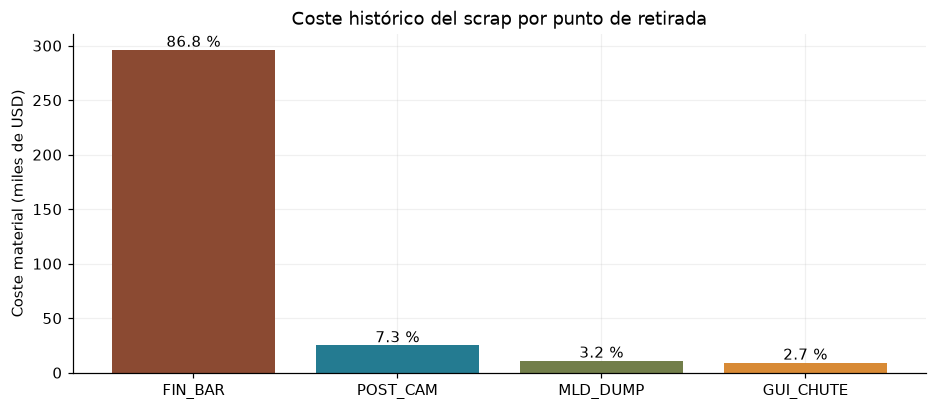

In [7]:
point_summary = scrap.groupby('collection_point_code', observed=True).agg(
    registros=('cost_usd','size'), conteo_registrado=('piece_count','sum'),
    kg=('quantity_kg','sum'), coste_usd=('cost_usd','sum'))
point_summary = point_summary.join(scrap_points[['collection_point_name','scrap_type','after_machine_code','usd_per_kg']])
point_summary['porcentaje_coste'] = 100*point_summary.coste_usd/point_summary.coste_usd.sum()
point_summary = point_summary.sort_values('coste_usd',ascending=False)
point_summary['porcentaje_acumulado'] = point_summary.porcentaje_coste.cumsum()
total_scrap_usd = float(scrap.cost_usd.sum())
final_scrap_usd = float(point_summary.loc['FIN_BAR','coste_usd'])
final_reject_rate = float(minute.FIN_BAR_piece_count.sum()/minute.bar_pieces.sum())
show(point_summary, 4)
explain(f'**Referencia:** {total_scrap_usd:,.2f} USD de scrap total; '
        f'{final_scrap_usd:,.2f} USD corresponden a barrita terminada '
        f'({100*final_scrap_usd/total_scrap_usd:.2f} %). '
        f'La retirada final equivale al {100*final_reject_rate:.3f} % de las piezas medidas allí. '
        '`MLD_DUMP` cuenta cargas de masa: su conteo no se suma a las barritas.')
fig, ax = plt.subplots(figsize=(10,4))
ax.bar(point_summary.index,point_summary.coste_usd/1000,color=[POINT_COLORS[p] for p in point_summary.index])
ax.set(ylabel='Coste material (miles de USD)',title='Coste histórico del scrap por punto de retirada')
for i,v in enumerate(point_summary.porcentaje_coste):
    ax.text(i,point_summary.coste_usd.iloc[i]/1000+3,f'{v:.1f} %',ha='center')
figure(fig,'03_pareto_coste')
export_table(point_summary,'coste_por_punto')


,dias_observados,scrap_cost_usd,FIN_BAR_cost_usd,coste_medio_dia_usd,tasa_rechazo_final_pct
minute_ts,,,,,
2026-07,20,104200.89402,88385.67782,5210.04470,1.42593
2026-08,21,112547.86710,98179.41462,5359.42224,1.51454
2026-09,22,111800.35304,99572.19414,5081.83423,1.45265
2026-10,2,12294.42690,9864.44329,6147.21345,1.65401


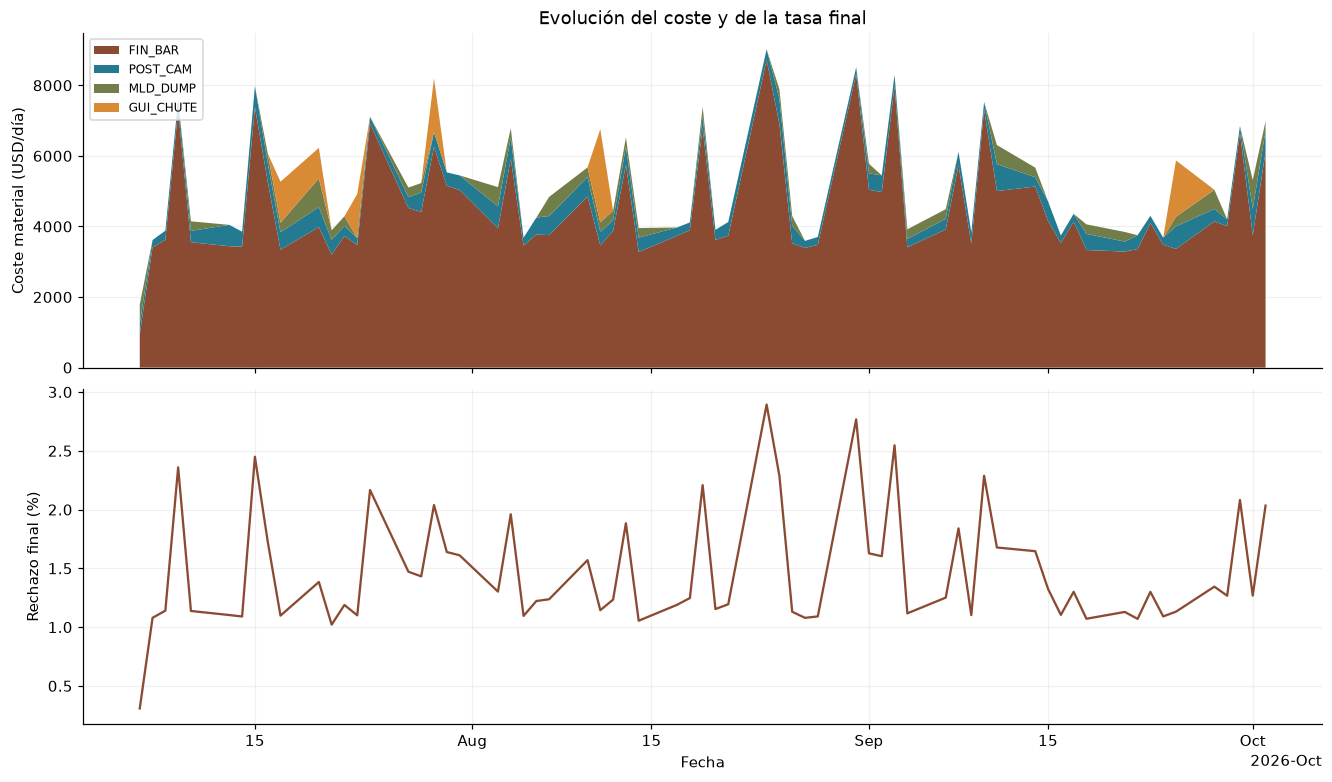

,scrap_cost_usd,FIN_BAR_piece_count,tasa_rechazo_final_pct
minute_ts,,,
2026-08-24,9023.06982,49838,2.89315
2026-08-31,8514.55915,47583,2.76739
2026-09-03,8295.84627,45636,2.54668
2026-07-29,8198.08470,35762,2.03820
2026-07-15,7979.54811,42205,2.44948
2026-08-25,7889.33477,39473,2.28654
2026-07-09,7594.01815,41725,2.35915
2026-09-10,7532.15867,41801,2.28796


**Interpretación:** octubre solo contiene los días presentes en los archivos y julio comienza después del inicio del mes. Para comparar meses se muestran días observados y coste por día. El coste por 1.000 barras OEE es una intensidad económica de referencia, no un rendimiento físico de toda la línea ni una cifra de margen perdido.

In [8]:
cost_columns = [f'{p}_cost_usd' for p in scrap_points.index]
sum_columns = cost_columns+['scrap_cost_usd','total_bars','bar_pieces','FIN_BAR_piece_count',
                         'bar_height_oos','bar_width_oos','bar_length_oos','core_height_oos']
daily = minute[sum_columns].groupby(minute.index.normalize()).sum()
daily['tasa_rechazo_final_pct'] = 100*ratio(daily.FIN_BAR_piece_count,daily.bar_pieces)
daily['tasa_altura_final_pct'] = 100*ratio(daily.bar_height_oos,daily.bar_pieces)
daily['coste_usd_por_1000_barras_oee'] = 1000*ratio(daily.scrap_cost_usd,daily.total_bars)
monthly = minute[sum_columns].groupby(minute.index.to_period('M')).sum()
monthly['dias_observados'] = pd.Series(days).groupby(pd.Series(days).dt.to_period('M')).size()
monthly['coste_medio_dia_usd'] = monthly.scrap_cost_usd/monthly.dias_observados
monthly['tasa_rechazo_final_pct'] = 100*ratio(monthly.FIN_BAR_piece_count,monthly.bar_pieces)
week_key = minute.index.to_period('W-SUN').start_time
weekly = minute[sum_columns].groupby(week_key).sum()
weekly.index.name='semana_inicio_lunes'
show(monthly[['dias_observados','scrap_cost_usd','FIN_BAR_cost_usd','coste_medio_dia_usd','tasa_rechazo_final_pct']])
fig,axs=plt.subplots(2,1,figsize=(12,7),sharex=True,layout='constrained')
points=point_summary.index.tolist()
axs[0].stackplot(daily.index,*[daily[f'{p}_cost_usd'].to_numpy() for p in points],
                 labels=points,colors=[POINT_COLORS[p] for p in points],linewidth=0)
axs[0].legend(fontsize=8,loc='upper left')
axs[0].set(ylabel='Coste material (USD/día)',title='Evolución del coste y de la tasa final')
axs[1].plot(daily.index,daily.tasa_rechazo_final_pct,color=COLORS[0])
axs[1].set(ylabel='Rechazo final (%)',xlabel='Fecha')
date_locator=mdates.AutoDateLocator(minticks=5,maxticks=9)
axs[1].xaxis.set_major_locator(date_locator)
axs[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(date_locator))
figure(fig,'03_coste_y_tasa_diarios')
show(daily.nlargest(8,'scrap_cost_usd')[['scrap_cost_usd','FIN_BAR_piece_count','tasa_rechazo_final_pct']])
export_table(daily,'resumen_diario')
export_table(weekly,'resumen_semanal')
export_table(monthly,'resumen_mensual')
explain('**Interpretación:** octubre solo contiene los días presentes en los archivos y julio comienza '
        'después del inicio del mes. Para comparar meses se muestran días observados y coste por día. '
        'El coste por 1.000 barras OEE es una intensidad económica de referencia, no un rendimiento físico '
        'de toda la línea ni una cifra de margen perdido.')


<a id="4-distribución-persistencia-e-incidencias"></a>

## 4. Distribución, persistencia e incidencias

Se llama **ventana habitual de referencia** a una ventana sin incidencias registradas cerca.
No significa que el proceso esté ajustado ni que no haya fallos sin registrar. Se usa una
exclusión retrospectiva configurable de 5 minutos antes y 20 después de cada episodio.
También se muestran otras ventanas para comprobar la sensibilidad a esta elección.
El coste dentro y fuera de esas ventanas es una partición temporal, no una atribución causal.


In [9]:
def event_mask(before=0, after=0, selected=None):
    mask = np.zeros(len(idx), dtype=bool)
    source = events if selected is None else selected
    for row in source.itertuples():
        mask |= ((idx >= row.started_at-pd.Timedelta(minutes=before)) &
                 (idx < row.ended_at+pd.Timedelta(minutes=after)))
    return pd.Series(mask,index=idx)
active_count = np.zeros(len(idx),dtype='int16')
for row in events.itertuples():
    active_count += ((idx>=row.started_at)&(idx<row.ended_at)).astype('int16')
minute['active_event_count']=active_count
minute['near_event']=event_mask(EVENT_BUFFER_BEFORE_MIN,EVENT_BUFFER_AFTER_MIN)
minute['reference_window']=~minute.near_event
context_rows=[]
for label, g in minute.groupby('near_event',observed=True):
    context_rows.append({'contexto':'Entorno de incidencia' if label else 'Referencia sin incidencia próxima',
                        'minutos':len(g),'coste_total_usd':g.scrap_cost_usd.sum(),
                        'coste_final_usd':g.FIN_BAR_cost_usd.sum(),
                        'piezas_medidas_final':g.bar_pieces.sum(),
                        'rechazo_final_pct':100*g.FIN_BAR_piece_count.sum()/g.bar_pieces.sum(),
                        'altura_final_pct':100*g.bar_height_oos.sum()/g.bar_pieces.sum()})
context_summary=pd.DataFrame(context_rows).set_index('contexto')
show(context_summary)
explain(f'Hay **{int((active_count>1).sum()):,} minutos con más de una incidencia activa**. '
        'Los costes asociados a cada código pueden solaparse y no deben sumarse como causas independientes.')
export_table(context_summary,'contextos_incidencia')


,minutos,coste_total_usd,coste_final_usd,piezas_medidas_final,rechazo_final_pct,altura_final_pct
contexto,,,,,,
Referencia sin incidencia próxima,52436,197090.82005,185856.80056,96390960,1.10170,1.06445
Entorno de incidencia,11914,143752.72101,110144.92930,18637459,3.37675,3.23262


Hay **133 minutos con más de una incidencia activa**. Los costes asociados a cada código pueden solaparse y no deben sumarse como causas independientes.

,bar_pieces,bar_height_oos,bar_height_rate_pct,bar_height_mean_mm,core_height_rate_pct,core_height_mean_mm
lane_no,,,,,,
31,3562474,478764,13.43909,17.01231,0.39606,13.99805
1,3564596,268095,7.52105,17.09608,0.39166,13.99796
2,3561283,194464,5.46050,17.13709,0.39090,13.99811
32,3564126,162940,4.57167,17.15876,0.38702,13.99804
3,3561685,151827,4.26279,17.16728,0.38900,13.99807
30,3562181,52445,1.47227,17.29224,0.39147,13.99807
28,3584041,22027,0.61459,17.38163,0.38797,13.99801
29,3571652,15243,0.42678,17.56191,0.38954,13.99803
27,3590260,14550,0.40526,17.62890,0.39551,13.99807


,antes_min,después_min,minutos_referencia,coste_total_referencia_usd,conteos_altura_referencia,porcentaje_altura_cinco_carriles,tasa_altura_referencia_pct
0,0,0,61394,261199.23493,1315746,88.78910,1.17482
1,0,2,60645,253682.99539,1279866,90.44478,1.14838
2,5,20,52436,197090.82005,1026035,96.67009,1.06445
3,10,30,47566,176864.64911,931575,96.67735,1.06731


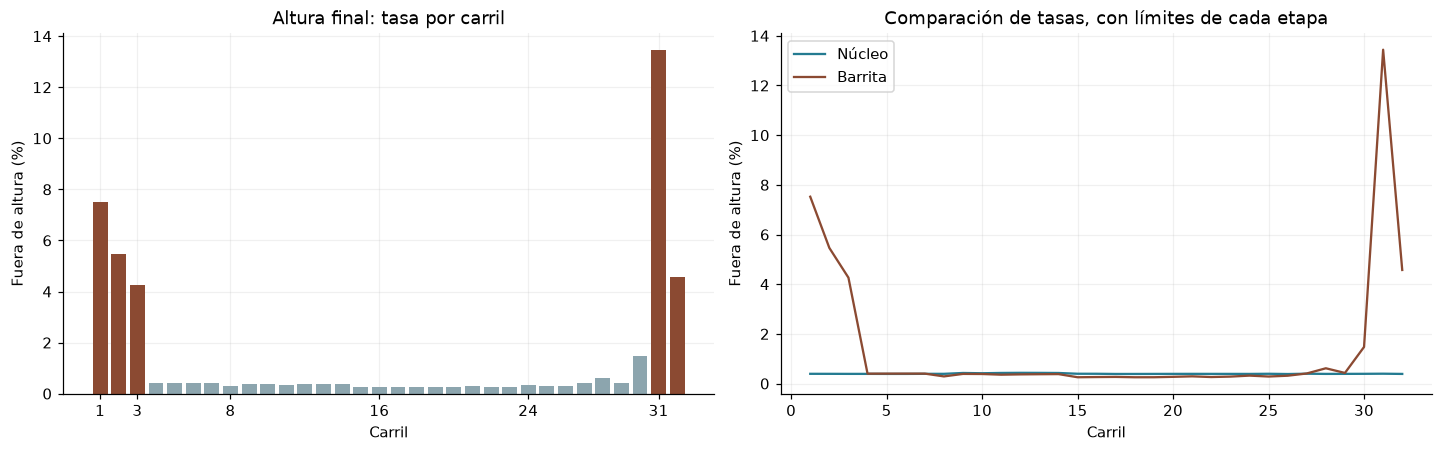

Los carriles [1, 2, 3, 31, 32] reúnen el **77.13 %** de los conteos finales de altura con el **15.49 %** de las piezas medidas. Se muestran tanto los seis carriles exteriores propuestos por el equipo como el subconjunto de cinco con mayor peso. La sensibilidad confirma si el patrón persiste con distintas exclusiones; no convierte el scrap restante en una cantidad fija ni en un ahorro recuperable íntegro.

In [10]:
bar = tables['fct_laser_bar_minute']
core = tables['fct_laser_core_minute']
def lane_summary(raw, mask=None):
    columns=['lane_no','minute_ts','pieces','height_oos','width_oos','length_oos','height_mm_avg']
    x=raw[columns].copy()
    if mask is not None:
        x=x[x.minute_ts.map(mask).fillna(False)]
    x['weighted_height']=x.height_mm_avg*x.pieces
    a=x.groupby('lane_no',observed=True)[['pieces','height_oos','width_oos','length_oos','weighted_height']].sum()
    a['height_rate_pct']=100*ratio(a.height_oos,a.pieces)
    a['height_mean_mm']=ratio(a.weighted_height,a.pieces)
    return a.drop(columns='weighted_height')
bar_lane=lane_summary(bar)
core_lane=lane_summary(core)
lane_comparison=bar_lane[['pieces','height_oos','height_rate_pct','height_mean_mm']].rename(
    columns=lambda c:'bar_'+c).join(core_lane[['height_rate_pct','height_mean_mm']].add_prefix('core_'))
show(lane_comparison.sort_values('bar_height_oos',ascending=False),10)
priority_lanes=[1,2,3,31,32]
all_edge_lanes=[1,2,3,30,31,32]
sensitivity=[]
for before,after in [(0,0),(0,2),(5,20),(10,30)]:
    mask=~event_mask(before,after)
    a=lane_summary(bar,mask)
    sensitivity.append({'antes_min':before,'después_min':after,
                        'minutos_referencia':int(mask.sum()),
                        'coste_total_referencia_usd':minute.loc[mask,'scrap_cost_usd'].sum(),
                        'conteos_altura_referencia':a.height_oos.sum(),
                        'porcentaje_altura_cinco_carriles':100*a.loc[priority_lanes,'height_oos'].sum()/a.height_oos.sum(),
                        'tasa_altura_referencia_pct':100*a.height_oos.sum()/a.pieces.sum()})
sensitivity=pd.DataFrame(sensitivity)
show(sensitivity)
edge_share=100*bar_lane.loc[priority_lanes,'height_oos'].sum()/bar_lane.height_oos.sum()
edge_volume=100*bar_lane.loc[priority_lanes,'pieces'].sum()/bar_lane.pieces.sum()
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axs[0].bar(bar_lane.index,bar_lane.height_rate_pct,
           color=[COLORS[0] if lane in priority_lanes else '#8ca5ae' for lane in bar_lane.index])
axs[0].set(title='Altura final: tasa por carril',xlabel='Carril',ylabel='Fuera de altura (%)',xticks=[1,3,8,16,24,31])
axs[1].plot(core_lane.index,core_lane.height_rate_pct,label='Núcleo',color=COLORS[1])
axs[1].plot(bar_lane.index,bar_lane.height_rate_pct,label='Barrita',color=COLORS[0])
axs[1].set(title='Comparación de tasas, con límites de cada etapa',xlabel='Carril',ylabel='Fuera de altura (%)')
axs[1].legend()
figure(fig,'04_carriles_altura')
explain(f'Los carriles {priority_lanes} reúnen el **{edge_share:.2f} %** de los conteos finales de altura '
        f'con el **{edge_volume:.2f} %** de las piezas medidas. Se muestran tanto los seis carriles '
        'exteriores propuestos por el equipo como el subconjunto de cinco con mayor peso. '
        'La sensibilidad confirma si el patrón persiste con distintas exclusiones; no convierte '
        'el scrap restante en una cantidad fija ni en un ahorro recuperable íntegro.')
export_table(lane_comparison,'comparacion_carriles')
export_table(sensitivity,'sensibilidad_ventanas_incidencia',index=False)


,scrap_cost_usd,bar_pieces,rechazo_final_pct,altura_final_pct
shift_code,,,,
A,259570.15052,57422670,2.35817,2.29868
B,81273.39053,57357589,0.58781,0.53794
CLEAN,0.00000,248160,0.00000,0.00000


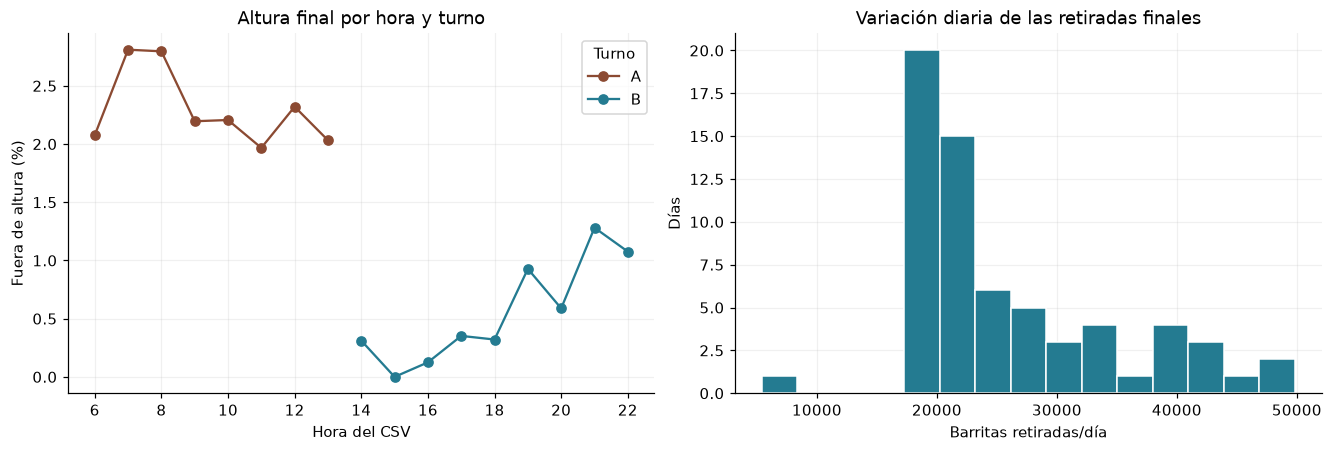

El turno A supera a B en tasa de altura en **61 de 65 días**. Las retiradas finales diarias van de 5,409 a 49,838, con mediana 22,363. Esto no prueba diferencias entre operarios ni un piso exacto de 19.000 barras diarias.

,minutos,coste_contemporaneo_usd,barras_oee,intensidad_usd_1000_barras
dough_batch_id,,,,
B-20260910-1562,30,3911.45933,57600,67.90728
B-20260930-2002,30,3121.27585,57600,54.18882
B-20260825-1153,30,2552.73782,50208,50.84325
B-20260831-1304,30,2544.39695,36480,69.74772
B-20260729-558,30,2430.55326,57600,42.19711
B-20260903-1399,30,2398.11355,57600,41.63392
B-20260908-1473,30,2373.11646,48000,49.43993
B-20260724-474,30,2081.19834,55104,37.76855


**Lotes:** esta tabla identifica el lote contextual en producción cuando se registra el coste. No atribuye la retirada final a ese lote de origen: haría falta alinear tiempos de residencia por etapa y conocer mezclas o cambios de lote. No debe usarse como etiqueta causal de lote.

In [11]:
shift_summary=minute.groupby('shift_code',observed=True)[sum_columns].sum()
shift_summary['rechazo_final_pct']=100*ratio(shift_summary.FIN_BAR_piece_count,shift_summary.bar_pieces)
shift_summary['altura_final_pct']=100*ratio(shift_summary.bar_height_oos,shift_summary.bar_pieces)
show(shift_summary[['scrap_cost_usd','bar_pieces','rechazo_final_pct','altura_final_pct']])
day_shift=minute.groupby([minute.index.normalize(),'shift_code'],observed=True)[['bar_pieces','bar_height_oos']].sum()
day_shift['rate']=ratio(day_shift.bar_height_oos,day_shift.bar_pieces)
shift_days=day_shift.rate.unstack()
a_worse_days=int((shift_days['A']>shift_days['B']).sum())
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for shift,color in [('A',COLORS[0]),('B',COLORS[1])]:
    g=minute[minute.shift_code==shift]
    aggregate=g.groupby(g.index.hour)[['bar_pieces','bar_height_oos']].sum()
    axs[0].plot(aggregate.index,100*ratio(aggregate.bar_height_oos,aggregate.bar_pieces),label=shift,color=color,marker='o')
axs[0].set(title='Altura final por hora y turno',xlabel='Hora del CSV',ylabel='Fuera de altura (%)')
axs[0].legend(title='Turno')
axs[1].hist(daily.FIN_BAR_piece_count,bins=15,color=COLORS[1],edgecolor='white')
axs[1].set(title='Variación diaria de las retiradas finales',xlabel='Barritas retiradas/día',ylabel='Días')
figure(fig,'04_turnos_y_distribucion_diaria')
explain(f'El turno A supera a B en tasa de altura en **{a_worse_days} de {len(shift_days)} días**. '
        f'Las retiradas finales diarias van de {daily.FIN_BAR_piece_count.min():,.0f} a '
        f'{daily.FIN_BAR_piece_count.max():,.0f}, con mediana {daily.FIN_BAR_piece_count.median():,.0f}. '
        'Esto no prueba diferencias entre operarios ni un piso exacto de 19.000 barras diarias.')
batch_context=minute.groupby('dough_batch_id',observed=True).agg(
    minutos=('scrap_cost_usd','size'),coste_contemporaneo_usd=('scrap_cost_usd','sum'),
    barras_oee=('total_bars','sum'))
batch_context['intensidad_usd_1000_barras']=1000*ratio(batch_context.coste_contemporaneo_usd,batch_context.barras_oee)
show(batch_context[batch_context.barras_oee>0].nlargest(8,'coste_contemporaneo_usd'))
explain('**Lotes:** esta tabla identifica el lote contextual en producción cuando se registra el coste. '
        'No atribuye la retirada final a ese lote de origen: haría falta alinear tiempos de residencia '
        'por etapa y conocer mezclas o cambios de lote. No debe usarse como etiqueta causal de lote.')
export_table(shift_summary,'resumen_turnos')
export_table(batch_context,'lotes_contextuales')


<a id="5-relaciones-con-el-proceso"></a>

## 5. Relaciones con el proceso

### 5.1. Localizar la aparición del desequilibrio de altura

Se comparan medias por carril de los dos láseres. El núcleo se desplaza hacia delante dos
minutos por reloj, nunca por posición de fila. Se exige que haya piezas en ambas etapas.
La diferencia estima el incremento entre estaciones para grupos alineados; no mide el
espesor de la misma pieza ni prueba por sí sola que el láser esté calibrado.


,carril,turno,piezas_alineadas,núcleo_mm,barrita_mm,incremento_mm
0,1,A,1490880,13.99988,16.90432,2.90444
1,1,B,1492020,14.00016,17.29278,3.29262
2,2,A,1489200,13.99994,16.95684,2.95689
3,2,B,1490460,14.00018,17.32247,3.32229
4,3,A,1488300,13.99990,16.99499,2.99509
5,3,B,1491180,14.00019,17.34430,3.34411
34,18,A,1501260,13.99989,18.67192,4.67203
35,18,B,1505040,14.00016,18.29370,4.29353
58,30,A,1489620,13.99991,17.15534,3.15544
59,30,B,1490760,14.00016,17.43487,3.43470


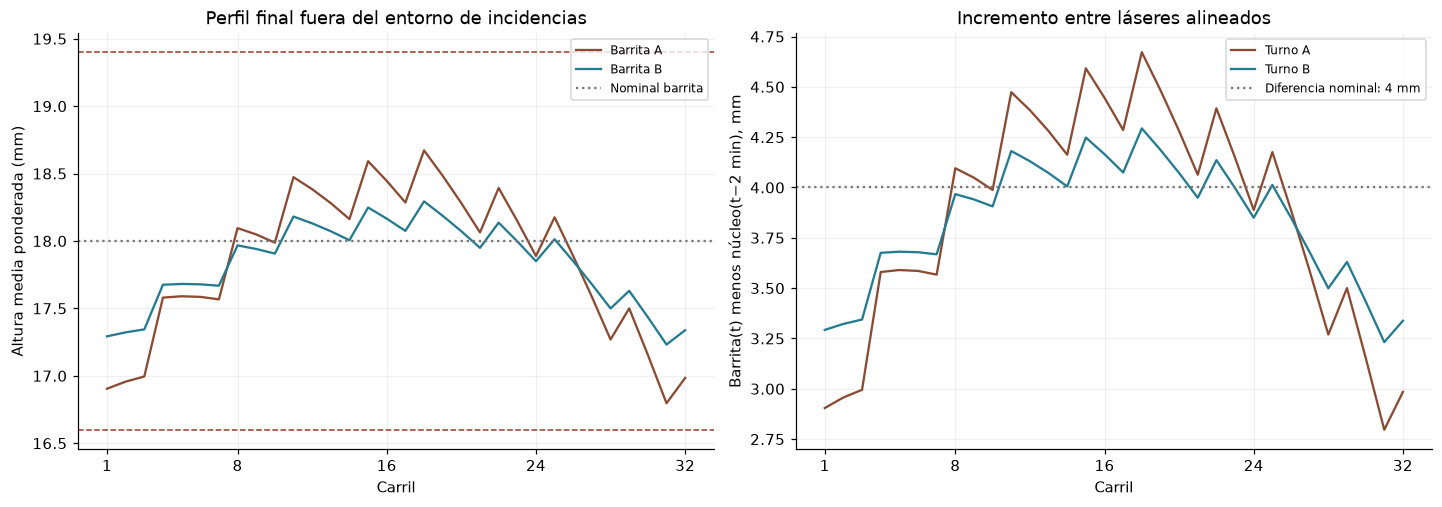

Entre los conteos finales alineables, **79.78 %** coinciden con grupos de núcleo dentro del intervalo y sin conteos de altura fuera de especificación. La evidencia sitúa una prioridad entre el láser del núcleo y el final: cobertura o medida. Hay que comprobar calibración y distribución antes de atribuir una avería concreta.

**Documentación del caso:** el HTML describe mayor depósito de la cortina en el centro y un desequilibrio que crece hasta la limpieza de las 14:00. Esta explicación se separa de lo calculado con los CSV. No demuestra que un ajuste específico vaya a eliminar todos los rechazos ni que la limpieza sea la única intervención posible.

In [12]:
bar_small=bar[['minute_ts','lane_no','pieces','height_mm_avg','height_oos']].rename(
    columns={'pieces':'bar_pieces','height_mm_avg':'bar_height_mm','height_oos':'bar_height_oos'})
core_small=core[['minute_ts','lane_no','pieces','height_mm_avg','height_oos']].rename(
    columns={'pieces':'core_pieces','height_mm_avg':'core_height_mm','height_oos':'core_height_oos'})
core_small['minute_ts']=core_small.minute_ts+pd.Timedelta(minutes=CORE_TO_BAR_LAG_MIN)
aligned=bar_small.merge(core_small,on=['minute_ts','lane_no'],how='left',validate='one_to_one')
aligned['valid_pair']=aligned.bar_pieces.gt(0)&aligned.core_pieces.gt(0)&aligned.core_height_mm.notna()
aligned['reference_window']=aligned.minute_ts.map(minute.reference_window)
aligned['shift_code']=aligned.minute_ts.map(minute.shift_code)
aligned['increment_mm']=(aligned.bar_height_mm-aligned.core_height_mm).where(aligned.valid_pair)
coating_rows=[]
for (lane,shift),g in aligned[aligned.valid_pair&aligned.reference_window].groupby(['lane_no','shift_code'],observed=True):
    if shift not in ['A','B']:
        continue
    w=g.bar_pieces
    coating_rows.append({'carril':lane,'turno':shift,'piezas_alineadas':w.sum(),
                          'núcleo_mm':np.average(g.core_height_mm,weights=w),
                          'barrita_mm':np.average(g.bar_height_mm,weights=w),
                          'incremento_mm':np.average(g.increment_mm,weights=w)})
coating_profile=pd.DataFrame(coating_rows)
show(coating_profile[coating_profile.carril.isin([1,2,3,18,30,31,32])],14)
fig,axs=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
bar_height_spec=specs[(specs.product_stage=='bar')&(specs.measure_name=='height')].iloc[0]
for shift,color in [('A',COLORS[0]),('B',COLORS[1])]:
    a=coating_profile[coating_profile.turno==shift].set_index('carril')
    axs[0].plot(a.index,a.barrita_mm,label=f'Barrita {shift}',color=color)
    axs[1].plot(a.index,a.incremento_mm,label=f'Turno {shift}',color=color)
for limit in [bar_height_spec.lsl_mm,bar_height_spec.usl_mm]:
    axs[0].axhline(limit,color='#993d2a',linestyle='--',linewidth=1)
axs[0].axhline(bar_height_spec.nominal_mm,color='#777',linestyle=':',label='Nominal barrita')
axs[0].set(title='Perfil final fuera del entorno de incidencias',xlabel='Carril',ylabel='Altura media ponderada (mm)')
axs[1].axhline(4,color='#777',linestyle=':',label='Diferencia nominal: 4 mm')
axs[1].set(title='Incremento entre láseres alineados',xlabel='Carril',ylabel='Barrita(t) menos núcleo(t−2 min), mm')
for ax in axs:
    ax.set_xticks([1,8,16,24,32]);ax.legend(fontsize=8)
figure(fig,'05_perfil_cobertura')
healthy_core=aligned.valid_pair&aligned.core_height_oos.eq(0)&aligned.core_height_mm.between(13,15)
aligned_oos=aligned.loc[aligned.valid_pair,'bar_height_oos'].sum()
healthy_core_oos=aligned.loc[healthy_core,'bar_height_oos'].sum()
explain(f'Entre los conteos finales alineables, **{100*healthy_core_oos/aligned_oos:.2f} %** coinciden '
        'con grupos de núcleo dentro del intervalo y sin conteos de altura fuera de especificación. '
        'La evidencia sitúa una prioridad entre el láser del núcleo y el final: cobertura o medida. '
        'Hay que comprobar calibración y distribución antes de atribuir una avería concreta.')
documented_pattern = ('the centre takes more chocolate than the edges' in html_text.lower()
                      or 'centre lanes take a thicker curtain than the edges' in html_text.lower())
check('HTML documenta desequilibrio de la cortina',documented_pattern)
explain('**Documentación del caso:** el HTML describe mayor depósito de la cortina en el centro '
        'y un desequilibrio que crece hasta la limpieza de las 14:00. Esta explicación se separa '
        'de lo calculado con los CSV. No demuestra que un ajuste específico vaya a eliminar '
        'todos los rechazos ni que la limpieza sea la única intervención posible.')
export_table(coating_profile,'perfil_cobertura_alineado',index=False)
del bar_small,core_small


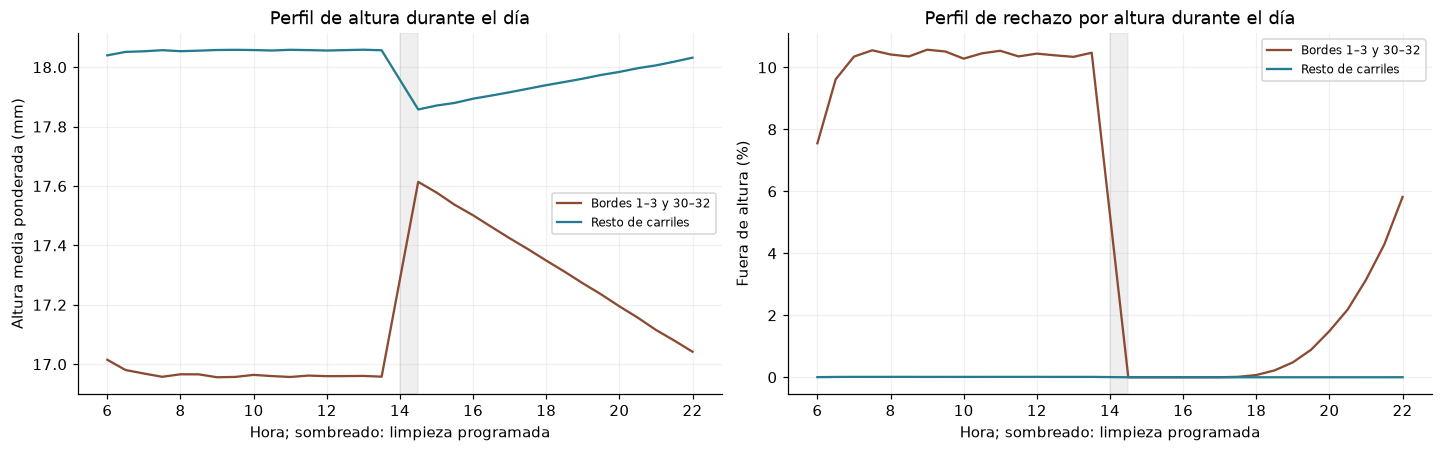

La comparación antes/después de las 14:00 también coincide con un cambio de turno. El perfil horario y la narrativa del caso son compatibles con un reajuste, pero los CSV no aíslan el efecto de la limpieza frente a otros cambios. La limpieza aquí es una variable contextual de calidad, no un análisis de ahorro por parada.

In [13]:
# Perfil horario habitual: comparar el centro con los seis carriles exteriores.
x=bar[['minute_ts','lane_no','pieces','height_mm_avg','height_oos']].copy()
profile_mask=minute.reference_window&minute.shift_code.astype(str).isin(['A','B'])
x=x[x.minute_ts.map(profile_mask)]
x['zona']=np.where(x.lane_no.isin(all_edge_lanes),'Bordes 1–3 y 30–32','Resto de carriles')
x['franja_hora']=x.minute_ts.dt.hour+x.minute_ts.dt.minute.floordiv(30)/2
x['weighted_height']=x.height_mm_avg*x.pieces
hour_profile=x.groupby(['franja_hora','zona'],observed=True)[['pieces','height_oos','weighted_height']].sum()
hour_profile['height_mean_mm']=ratio(hour_profile.weighted_height,hour_profile.pieces)
hour_profile['height_rate_pct']=100*ratio(hour_profile.height_oos,hour_profile.pieces)
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained')
for zone,color in [('Bordes 1–3 y 30–32',COLORS[0]),('Resto de carriles',COLORS[1])]:
    a=hour_profile.xs(zone,level='zona')
    axs[0].plot(a.index,a.height_mean_mm,label=zone,color=color)
    axs[1].plot(a.index,a.height_rate_pct,label=zone,color=color)
for ax in axs:
    ax.axvspan(14,14.5,color='#999',alpha=.15)
    ax.set(xlabel='Hora; sombreado: limpieza programada',xticks=[6,8,10,12,14,16,18,20,22])
    ax.legend(fontsize=8)
axs[0].set(title='Perfil de altura durante el día',ylabel='Altura media ponderada (mm)')
axs[1].set(title='Perfil de rechazo por altura durante el día',ylabel='Fuera de altura (%)')
figure(fig,'05_evolucion_respecto_limpieza')
export_table(hour_profile,'perfil_horario_carriles')
explain('La comparación antes/después de las 14:00 también coincide con un cambio de turno. '
        'El perfil horario y la narrativa del caso son compatibles con un reajuste, pero los CSV '
        'no aíslan el efecto de la limpieza frente a otros cambios. La limpieza aquí es una '
        'variable contextual de calidad, no un análisis de ahorro por parada.')
del x


### 5.2. Señales asociadas a otros mecanismos de scrap

La selección de señales usa los mecanismos del catálogo: humedad y alimentación para cámaras,
presión/caudal de crema para núcleo, caramelo para altura, sincronización para guillotina y
caudales de chocolate para barrita. Se muestran contrastes descriptivos con exposición.
Los umbrales son referencias explícitas del caso o filtros exploratorios, no alarmas validadas.


In [14]:
def descriptive_contrast(name, condition, target, threshold_note):
    rows=[]
    for flag in [True,False]:
        g=minute.loc[condition.eq(flag)]
        rows.append({'hipótesis':name,'condición':flag,'minutos':len(g),
                     'coste_punto_usd':g[f'{target}_cost_usd'].sum(),
                     'coste_por_minuto_usd':g[f'{target}_cost_usd'].mean(),
                     'referencia':threshold_note})
    return rows
contrasts=[]
contrasts += descriptive_contrast('Caramelo caliente y rodillo abierto',
    minute.CAR_TEMP_C.gt(58)&minute.CAR_ROLLER_GAP_MM.gt(3.5),'FIN_BAR','Catálogo: >58 °C y >3,5 mm')
contrasts += descriptive_contrast('Crema: presión alta y caudal bajo',
    minute.BCM_PRESSURE_BAR.gt(1.8)&minute.BCM_FLOW_KG_MIN.lt(3.5),'FIN_BAR','Filtro exploratorio: >1,8 bar y <3,5 kg/min')
contrasts += descriptive_contrast('Guillotina desincronizada',
    minute.GUI_PHASE_ERROR_MS.abs().gt(15),'GUI_CHUTE','Catálogo: error absoluto >15 ms')
contrasts += descriptive_contrast('Masa seca',
    minute.MIX_MOISTURE_PCT.lt(17.6),'POST_CAM','Catálogo: humedad <17,6 %; efecto con retraso')
contrasts=pd.DataFrame(contrasts)
show(contrasts,8)
vision_summary=pd.concat([
    tables[name].groupby(['camera_code','severity'],observed=True).size().rename('eventos').reset_index().assign(tipo=kind)
    for kind,name in [('Huecos','fct_vision_gap'),('Grietas','fct_vision_crack')]],ignore_index=True)
show(vision_summary,12)
explain('Estos contrastes son contemporáneos y pueden incluir paradas o producto en tránsito. '
        'No se interpretan como capacidad de anticipación. Los eventos de cámara no se convierten '
        'directamente en barritas rechazadas: un hueco puede afectar a varias piezas y las '
        'detecciones de distintas estaciones pueden referirse al mismo material.')
export_table(contrasts,'contrastes_mecanismos',index=False)
export_table(vision_summary,'eventos_camara',index=False)


,hipótesis,condición,minutos,coste_punto_usd,coste_por_minuto_usd,referencia
0,Caramelo caliente y rodillo abierto,True,73,13956.84943,191.18972,"Catálogo: >58 °C y >3,5 mm"
1,Caramelo caliente y rodillo abierto,False,64277,282044.88043,4.38796,"Catálogo: >58 °C y >3,5 mm"
2,Crema: presión alta y caudal bajo,True,84,10174.92235,121.13003,"Filtro exploratorio: >1,8 bar y <3,5 kg/min"
3,Crema: presión alta y caudal bajo,False,64266,285826.80751,4.44756,"Filtro exploratorio: >1,8 bar y <3,5 kg/min"
4,Guillotina desincronizada,True,96,8878.29957,92.48229,Catálogo: error absoluto >15 ms
5,Guillotina desincronizada,False,64254,161.79385,0.00252,Catálogo: error absoluto >15 ms
6,Masa seca,True,1157,1023.48005,0.88460,"Catálogo: humedad <17,6 %; efecto con retraso"
7,Masa seca,False,63193,23936.63774,0.37879,"Catálogo: humedad <17,6 %; efecto con retraso"


,camera_code,severity,eventos,tipo
0,CAM_POST,high,5136,Huecos
1,CAM_POST,medium,4766,Huecos
2,CAM_PRE,high,4856,Huecos
3,CAM_PRE,low,1802,Huecos
4,CAM_PRE,medium,4657,Huecos
5,CAM_POST,high,3259,Grietas
6,CAM_POST,medium,10712,Grietas


Estos contrastes son contemporáneos y pueden incluir paradas o producto en tránsito. No se interpretan como capacidad de anticipación. Los eventos de cámara no se convierten directamente en barritas rechazadas: un hueco puede afectar a varias piezas y las detecciones de distintas estaciones pueden referirse al mismo material.

,evento,máquina_registrada,código,inicio,fin,duración_declarada_min,duración_reloj_min,coste_coincidente_usd,altura_final_coincidente
229,178,ENR,P-ENR-TEMPER,2026-08-25 07:10:00,2026-08-25 07:46:00,36.0,36.0,3879.58831,21093
305,150,CAR,P-CAR-HOT,2026-09-10 21:02:00,2026-09-10 21:19:00,17.0,17.0,3414.05797,19488
277,148,CAR,P-CAR-HOT,2026-09-03 19:28:00,2026-09-03 19:43:00,15.0,15.0,3097.63355,17675
371,152,CAR,P-CAR-HOT,2026-09-30 17:03:00,2026-09-30 17:16:00,13.0,13.0,2654.15233,15129
218,151,CAR,P-CAR-HOT,2026-08-24 08:19:00,2026-08-24 08:32:00,13.0,13.0,2470.89517,14096
105,149,CAR,P-CAR-HOT,2026-07-29 12:48:00,2026-07-29 13:03:00,15.0,15.0,2422.45842,13351
386,181,ENR,P-ENR-BOTTOM,2026-10-02 14:51:00,2026-10-02 15:03:00,12.0,12.0,1854.12767,10588
313,143,CAR,P-CAR-COLD,2026-09-14 07:25:00,2026-09-14 07:51:00,26.0,26.0,1851.11060,10536
104,104,OVN,P-OVN-ZONE,2026-07-29 12:37:00,2026-07-29 12:59:00,22.0,22.0,1789.18775,9177
87,122,BCM,P-BCM-BLOCK,2026-07-24 19:31:00,2026-07-24 19:44:00,13.0,13.0,1759.68837,10048


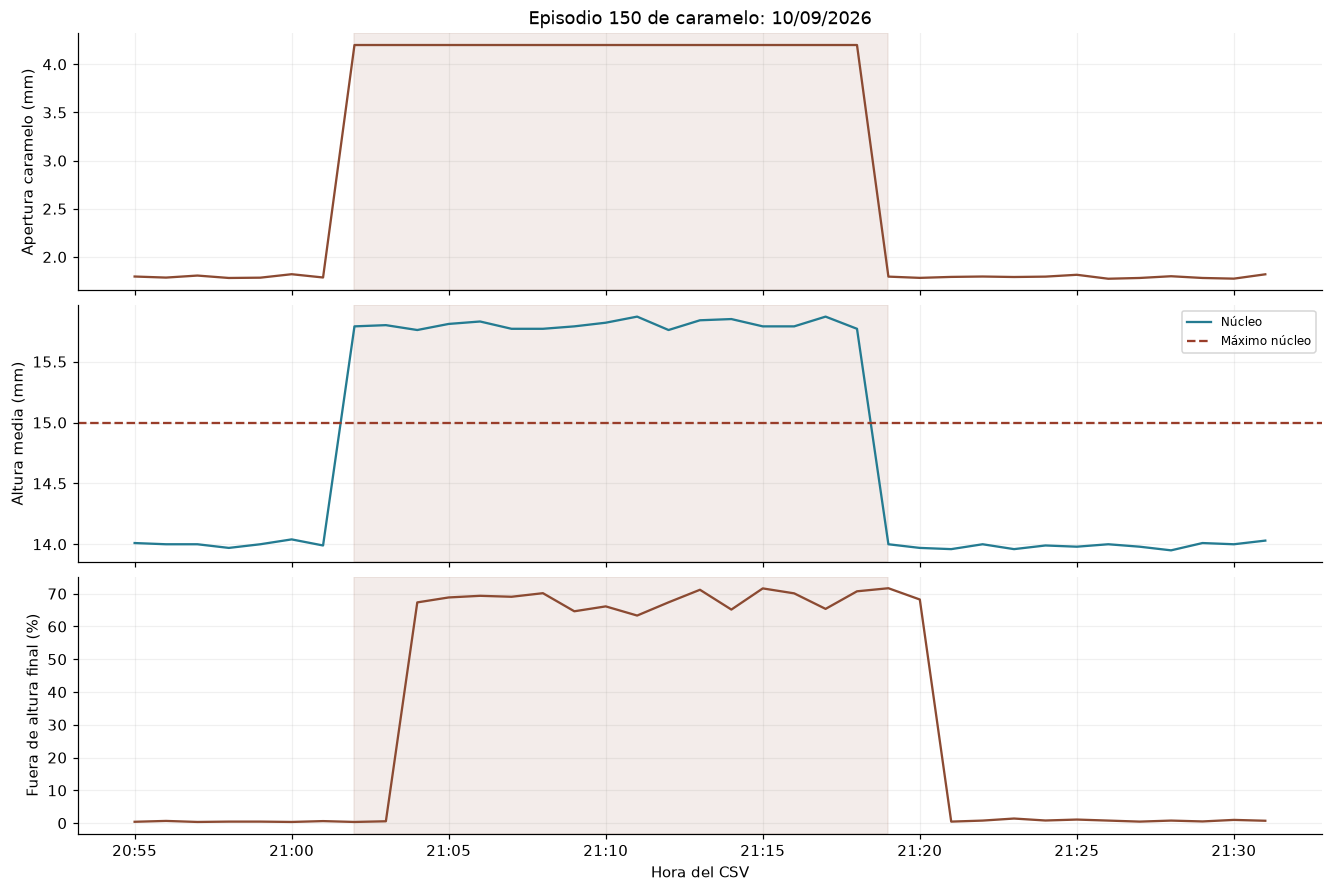

**Lectura del episodio:** observar el cambio del parámetro, la desviación del núcleo y la llegada posterior al láser final ayuda a localizar el proceso implicado. Los costes de esta tabla incluyen cualquier otro evento simultáneo y no se suman para afirmar cuánto causó cada máquina.

In [15]:
# Episodios con su coste coincidente: tabla de investigación, no de atribución exclusiva.
event_rows=[]
for e in events.itertuples():
    g=minute.loc[(minute.index>=e.started_at)&(minute.index<e.ended_at)]
    event_rows.append({'evento':e.problem_event_id,'máquina_registrada':e.machine_code,
                       'código':e.problem_code,'inicio':e.started_at,'fin':e.ended_at,
                       'duración_declarada_min':e.duration_s/60,
                       'duración_reloj_min':(e.ended_at-e.started_at).total_seconds()/60,
                       'coste_coincidente_usd':g.scrap_cost_usd.sum(),
                       'altura_final_coincidente':g.bar_height_oos.sum()})
event_association=pd.DataFrame(event_rows)
show(event_association.sort_values('coste_coincidente_usd',ascending=False),10)
candidate=event_association[event_association['código']=='P-CAR-HOT'].sort_values('coste_coincidente_usd',ascending=False)
if len(candidate):
    e=candidate.iloc[0]
    q=minute.loc[e.inicio-pd.Timedelta(minutes=7):e.fin+pd.Timedelta(minutes=12)]
    fig,axs=plt.subplots(3,1,figsize=(12,8),sharex=True,layout='constrained')
    axs[0].plot(q.index,q.CAR_ROLLER_GAP_MM,color=COLORS[0])
    axs[0].set(ylabel='Apertura caramelo (mm)',title=f'Episodio {int(e.evento)} de caramelo: {e.inicio:%d/%m/%Y}')
    axs[1].plot(q.index,q.core_height_mean_mm,color=COLORS[1],label='Núcleo')
    axs[1].axhline(15,color='#993d2a',linestyle='--',label='Máximo núcleo')
    axs[1].set(ylabel='Altura media (mm)');axs[1].legend(fontsize=8)
    axs[2].plot(q.index,q.bar_height_rate*100,color=COLORS[0])
    axs[2].set(ylabel='Fuera de altura final (%)',xlabel='Hora del CSV')
    axs[2].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    for ax in axs:
        ax.axvspan(e.inicio,e.fin,color=COLORS[0],alpha=.1)
    figure(fig,'05_episodio_caramelo')
export_table(event_association,'ventanas_eventos',index=False)
explain('**Lectura del episodio:** observar el cambio del parámetro, la desviación del núcleo '
        'y la llegada posterior al láser final ayuda a localizar el proceso implicado. '
        'Los costes de esta tabla incluyen cualquier otro evento simultáneo y no se suman '
        'para afirmar cuánto causó cada máquina.')


<a id="6-viabilidad-de-anticipación"></a>

## 6. Viabilidad de anticipación

### 6.1. Momento de decisión y objetivos candidatos

Se plantea una **alerta operativa al terminar el minuto t**, usando la telemetría de la línea
disponible hasta t, para anticipar el scrap registrado en los minutos **t+1 a t+H**. Esto es
distinto de predecir el destino de producto que acaba de entrar en una estación: no se sigue
una cohorte individual. Parte del material futuro puede estar ya comprometido y el margen
de actuación debe evaluarse antes de atribuir ahorro.

El horizonte H es configurable (10 minutos inicialmente). Se exploran presencia, importe
y coste alto. La presencia de cualquier scrap puede ser demasiado frecuente para una
clasificación útil. El umbral de coste alto se calcula solo con el primer tramo temporal.
Se excluyen ventanas incompletas o que incluyen minutos de limpieza programada.


In [16]:
def future_sum(series, horizon):
    # Desplazar el reloj: en t se toma la observación original de t+k.
    parts=[series.shift(-k,freq='min').reindex(idx).rename(k) for k in range(1,horizon+1)]
    return pd.concat(parts,axis=1).sum(axis=1,min_count=horizon)
def past_complete(series, lookback):
    parts=[series.shift(k,freq='min').reindex(idx).notna() for k in range(lookback+1)]
    return pd.concat(parts,axis=1).all(axis=1)
H=FORECAST_HORIZON_MIN
target_frame=pd.DataFrame(index=idx)
target_frame['future_scrap_cost_usd']=future_sum(minute.scrap_cost_usd,H)
target_frame['future_final_cost_usd']=future_sum(minute.FIN_BAR_cost_usd,H)
target_frame['future_final_pieces_measured']=future_sum(minute.bar_pieces,H)
target_frame['future_final_reject_pieces']=future_sum(minute.FIN_BAR_piece_count,H)
target_frame['future_final_reject_rate']=ratio(target_frame.future_final_reject_pieces,
                                             target_frame.future_final_pieces_measured)
planned_production=minute.shift_code.astype(str).isin(['A','B']).astype(int)
target_frame['future_planned_minutes']=future_sum(planned_production,H)
target_frame['valid_window']=(target_frame.future_scrap_cost_usd.notna()
    &target_frame.future_planned_minutes.eq(H)&planned_production.eq(1)
    &past_complete(minute.scrap_cost_usd,LOOKBACK_MIN))
n_train=int(len(days)*TRAIN_FRACTION)
n_validation=int(len(days)*VALIDATION_FRACTION)
check('Hay días para las tres particiones', n_train>0 and n_validation>0 and n_train+n_validation<len(days),fatal=True)
day_fold=pd.Series('test',index=days)
day_fold.iloc[:n_train]='train'
day_fold.iloc[n_train:n_train+n_validation]='validation'
fold=pd.Series(idx.normalize().map(day_fold),index=idx,name='partición')
# Exigir historia y objetivo completos dentro de una misma partición.
fold_consistent=pd.Series(True,index=idx)
for k in range(-LOOKBACK_MIN,H+1):
    fold_consistent &= fold.shift(-k,freq='min').reindex(idx).eq(fold)
target_frame['valid_window'] &= fold_consistent
target_frame['split']=fold
train_mask=target_frame.valid_window&fold.eq('train')
high_cost_threshold=float(target_frame.loc[train_mask,'future_scrap_cost_usd'].quantile(HIGH_SCRAP_QUANTILE))
target_frame['future_any_scrap']=target_frame.future_scrap_cost_usd.gt(0).where(target_frame.valid_window)
target_frame['future_high_scrap']=target_frame.future_scrap_cost_usd.gt(high_cost_threshold).where(target_frame.valid_window)
check('Objetivos no cruzan limpieza o huecos', target_frame.loc[target_frame.valid_window,'future_planned_minutes'].eq(H).all(),fatal=True)
check('Objetivo futuro no incluye el minuto actual',
      np.isclose(target_frame.future_scrap_cost_usd.iloc[0],minute.scrap_cost_usd.iloc[1:H+1].sum()),fatal=True)
split_rows=[]
for label in ['train','validation','test']:
    g=target_frame[target_frame.valid_window&fold.eq(label)]
    split_rows.append({'partición':label,'desde':g.index.min(),'hasta':g.index.max(),
                       'días':len(day_fold[day_fold==label]),'ventanas_válidas':len(g),
                       'presencia_scrap_pct':100*g.future_any_scrap.mean(),
                       'coste_alto_pct':100*g.future_high_scrap.mean(),
                       'coste_futuro_mediana_usd':g.future_scrap_cost_usd.median()})
split_summary=pd.DataFrame(split_rows).set_index('partición')
show(split_summary)
explain(f'El umbral exploratorio de coste alto es **{high_cost_threshold:.2f} USD en {H} minutos**, '
        f'cuantil {HIGH_SCRAP_QUANTILE:.0%} de train. No es una alarma validada. '
        'Las ventanas futuras se solapan: sus costes no pueden sumarse para calcular el histórico '
        'ni para valorar alertas repetidas. La intensidad de producción futura es solo parte del '
        'objetivo y de su validez, nunca una entrada disponible en t.')
presence_train=float(split_summary.loc['train','presencia_scrap_pct'])
explain(f'**Elección del objetivo:** el {presence_train:.2f} % de las ventanas train contiene '
        'algún scrap. Un clasificador que avisara siempre de scrap alcanzaría esa exactitud '
        'sin discriminar el riesgo. El importe, la intensidad o el exceso sobre el patrón '
        'habitual son candidatos que conviene comparar, además de estudiar precisión, '
        'recobrado y coste de las alertas en vez de exactitud aislada.')
export_table(split_summary,'propuesta_particiones_temporales')
export_table(day_fold.rename_axis('fecha').to_frame(),'particion_por_dia')


,desde,hasta,días,ventanas_válidas,presencia_scrap_pct,coste_alto_pct,coste_futuro_mediana_usd
partición,,,,,,,
train,2026-07-06 06:20:00,2026-09-04 22:19:00,45,41400,96.37440,10.00000,43.07920
validation,2026-09-07 06:20:00,2026-09-17 22:19:00,9,8280,97.02899,8.15217,53.56003
test,2026-09-18 06:20:00,2026-10-02 22:19:00,11,10120,95.79051,9.15020,44.02919


El umbral exploratorio de coste alto es **75.46 USD en 10 minutos**, cuantil 90% de train. No es una alarma validada. Las ventanas futuras se solapan: sus costes no pueden sumarse para calcular el histórico ni para valorar alertas repetidas. La intensidad de producción futura es solo parte del objetivo y de su validez, nunca una entrada disponible en t.

**Elección del objetivo:** el 96.37 % de las ventanas train contiene algún scrap. Un clasificador que avisara siempre de scrap alcanzaría esa exactitud sin discriminar el riesgo. El importe, la intensidad o el exceso sobre el patrón habitual son candidatos que conviene comparar, además de estudiar precisión, recobrado y coste de las alertas en vez de exactitud aislada.

### 6.2. Disponibilidad y riesgo de fuga de información

El histórico completo se usa para describir el negocio. Las asociaciones orientadas a elegir
señales y horizontes se calculan en **train**. No se entrena ni se evalúa ningún modelo aquí.
Como el diagnóstico global ya describe el histórico, la confirmación final de una solución
debe hacerse con un protocolo congelado y, si es posible, un periodo posterior independiente.

Todas las máquinas pueden aportar telemetría actual a una previsión del riesgo futuro global.
En cambio, si la decisión se traslada a la entrada de una estación para una cohorte concreta,
habrá que restringir las variables a lo conocido para esa cohorte en ese punto.


In [17]:
availability=parameter[['parameter_code','machine_code','unit','is_primary']].copy()
availability['disponible_desde']='Fin del minuto de lectura, si la adquisición es online'
availability['uso_propuesto']='Candidato para riesgo futuro global; validar disponibilidad real'
availability['advertencia']='Lecturas posteriores a t excluidas; no representan trazabilidad de una pieza'
additional=pd.DataFrame([
 {'parameter_code':'shift_code / hora / calendario','machine_code':'LINE','unit':'contexto',
  'disponible_desde':'Calendario conocido antes de t','uso_propuesto':'Contexto y control de patrones por turno',
  'advertencia':'El cambio de turno coincide con limpieza; no es una causa por sí mismo'},
 {'parameter_code':'lane_no / medidas de láser pasadas','machine_code':'LSR_CORE / LSR_BAR','unit':'carril / mm',
  'disponible_desde':'Tras la detección; con su latencia',
  'uso_propuesto':'Vigilancia y feedback para ventanas siguientes',
  'advertencia':'La medida final del mismo producto es resultado, no predictor temprano'},
 {'parameter_code':'cost_usd / piece_count / quantity_kg','machine_code':'Puntos de scrap','unit':'USD / piezas / kg',
  'disponible_desde':'Después de la retirada y su registro','uso_propuesto':'Objetivos y valoración; pasado solo si está disponible',
  'advertencia':'Nunca incluir el resultado de la ventana que se quiere predecir'},
 {'parameter_code':'problem_code / ended_at / duration_s / note','machine_code':'Registro de episodios','unit':'etiqueta',
  'disponible_desde':'Registro de la incidencia, potencialmente posterior a su inicio',
  'uso_propuesto':'Análisis retrospectivo y etiquetas parciales',
  'advertencia':'No asumir que diagnóstico, fin o duración eran conocidos en t'}])
availability=pd.concat([availability,additional],ignore_index=True)
show(availability.tail(4),4)
explain('**Estación sospechosa:** los códigos de incidencias son etiquetas parciales del registro. '
        'Puede haber varios códigos a la vez y problemas persistentes sin código. No sirven como '
        'verdad completa de la causa única. Un modelo por estación es una opción de diseño, '
        'no una condición necesaria que el EDA imponga para localizar señales.')
export_table(availability,'disponibilidad_variables',index=False)


,parameter_code,machine_code,unit,is_primary,disponible_desde,uso_propuesto,advertencia
51,shift_code / hora / calendario,LINE,contexto,NaN,Calendario conocido antes de t,Contexto y control de patrones por turno,El cambio de turno coincide con limpieza; no es una causa por sí mismo
52,lane_no / medidas de láser pasadas,LSR_CORE / LSR_BAR,carril / mm,NaN,Tras la detección; con su latencia,Vigilancia y feedback para ventanas siguientes,"La medida final del mismo producto es resultado, no predictor temprano"
53,cost_usd / piece_count / quantity_kg,Puntos de scrap,USD / piezas / kg,NaN,Después de la retirada y su registro,Objetivos y valoración; pasado solo si está disponible,Nunca incluir el resultado de la ventana que se quiere predecir
54,problem_code / ended_at / duration_s / note,Registro de episodios,etiqueta,NaN,"Registro de la incidencia, potencialmente posterior a su inicio",Análisis retrospectivo y etiquetas parciales,"No asumir que diagnóstico, fin o duración eran conocidos en t"


**Estación sospechosa:** los códigos de incidencias son etiquetas parciales del registro. Puede haber varios códigos a la vez y problemas persistentes sin código. No sirven como verdad completa de la causa única. Un modelo por estación es una opción de diseño, no una condición necesaria que el EDA imponga para localizar señales.

,hipótesis,parámetro,resultado,adelanto_min,rho_spearman,pares
23,Apertura caramelo y altura final,CAR_ROLLER_GAP_MM,bar_height_rate,2,-0.08939,41972
28,Sincronización y retirada de guillotina,GUI_PHASE_ERROR_MS,GUI_CHUTE_cost_usd,0,0.07809,43200
29,Sincronización y retirada de guillotina,GUI_PHASE_ERROR_MS,GUI_CHUTE_cost_usd,1,0.07729,43155
9,Presión de alimentación y huecos,DST_FEED_PRESSURE_BAR,gap_CAM_PRE_events,2,-0.07691,43110
30,Sincronización y retirada de guillotina,GUI_PHASE_ERROR_MS,GUI_CHUTE_cost_usd,2,0.06926,43110
10,Presión de alimentación y huecos,DST_FEED_PRESSURE_BAR,gap_CAM_PRE_events,5,-0.06538,42975
8,Presión de alimentación y huecos,DST_FEED_PRESSURE_BAR,gap_CAM_PRE_events,1,-0.06537,43155
5,Humedad y grietas,MIX_MOISTURE_PCT,crack_events,18,-0.06192,42390
6,Humedad y grietas,MIX_MOISTURE_PCT,crack_events,20,-0.05890,42300
31,Sincronización y retirada de guillotina,GUI_PHASE_ERROR_MS,GUI_CHUTE_cost_usd,5,0.05351,42975


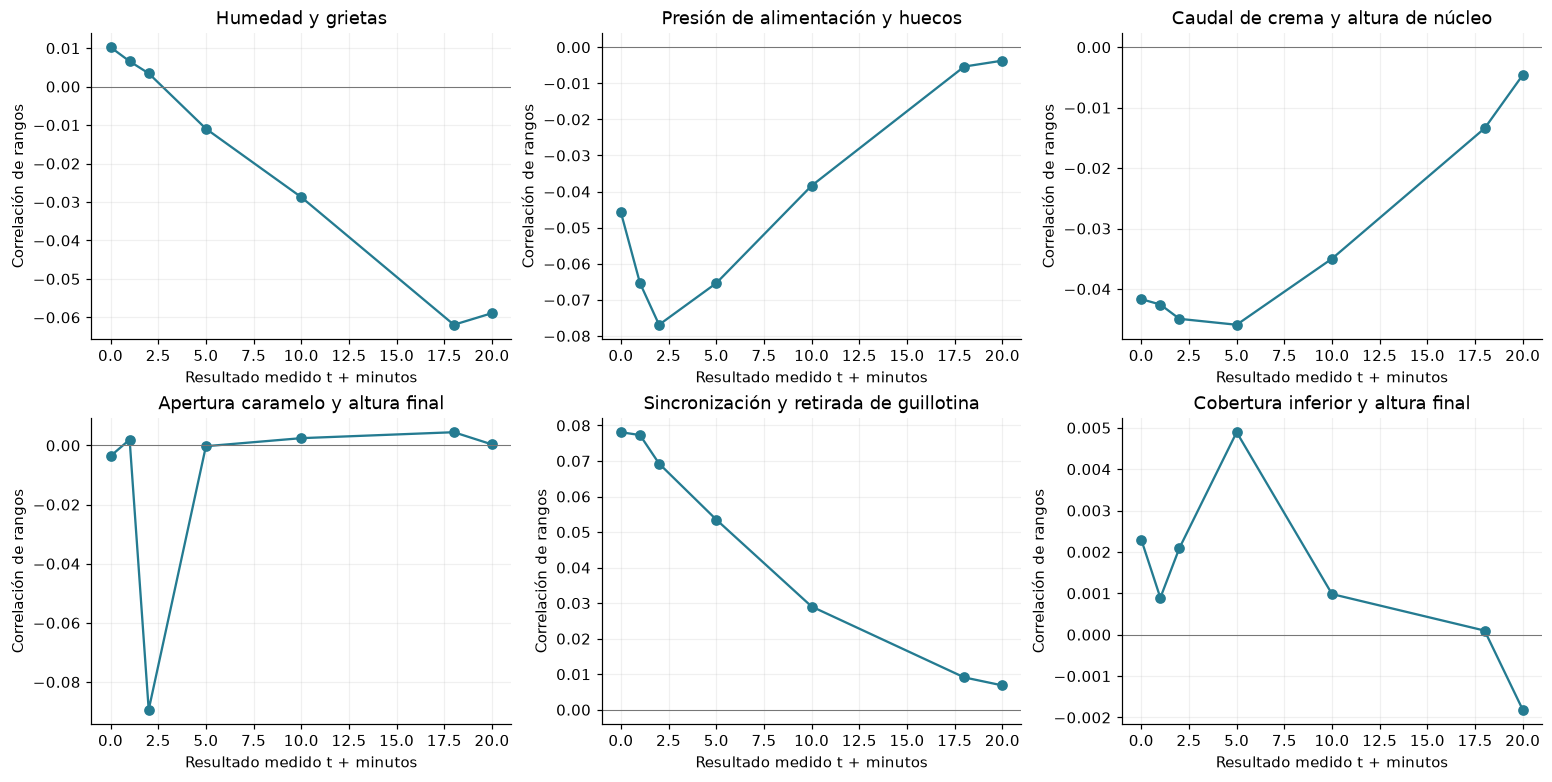

**Límite:** un adelanto positivo indica asociación con una observación posterior; no garantiza capacidad predictiva ni tiempo suficiente para corregir el producto. La autocorrelación, la producción/parada simultánea y los episodios largos pueden explicar parte de la relación. Se exploran mecanismos prefijados y no se atribuye causalidad por escoger el máximo de muchos desfases.

In [18]:
# Correlaciones de rangos sin scipy. Se reportan tamaños y no p-valores de minutos dependientes.
def rank_correlation(a,b,mask):
    pair=pd.concat([a.rename('a'),b.rename('b')],axis=1).loc[mask].dropna()
    if len(pair)<30 or pair.a.nunique()<2 or pair.b.nunique()<2:
        return np.nan,len(pair)
    return pair.a.rank().corr(pair.b.rank()),len(pair)
development=fold.eq('train')&minute.shift_code.astype(str).isin(['A','B'])
mechanism_pairs=[
 ('Humedad y grietas','MIX_MOISTURE_PCT','crack_events',False),
 ('Presión de alimentación y huecos','DST_FEED_PRESSURE_BAR','gap_CAM_PRE_events',False),
 ('Caudal de crema y altura de núcleo','BCM_FLOW_KG_MIN','core_height_rate',False),
 ('Apertura caramelo y altura final','CAR_ROLLER_GAP_MM','bar_height_rate',False),
 ('Sincronización y retirada de guillotina','GUI_PHASE_ERROR_MS','GUI_CHUTE_cost_usd',True),
 ('Cobertura inferior y altura final','ENR_BOTTOM_KG_MIN','bar_height_rate',False)]
lags=[0,1,2,5,10,18,20]
lag_rows=[]
for hypothesis,feature,target,absolute in mechanism_pairs:
    x=minute[feature].abs() if absolute else minute[feature]
    for lag in lags:
        y=minute[target].shift(-lag,freq='min').reindex(idx)
        same_fold=fold.shift(-lag,freq='min').reindex(idx).eq('train')
        rho,n=rank_correlation(x,y,development&same_fold)
        lag_rows.append({'hipótesis':hypothesis,'parámetro':feature,'resultado':target,
                         'adelanto_min':lag,'rho_spearman':rho,'pares':n})
lag_scan=pd.DataFrame(lag_rows)
show(lag_scan.sort_values('rho_spearman',key=lambda x:x.abs(),ascending=False),12)
fig,axs=plt.subplots(2,3,figsize=(14,7),layout='constrained')
for ax,(hypothesis,_,_,_) in zip(axs.flat,mechanism_pairs):
    a=lag_scan[lag_scan['hipótesis']==hypothesis]
    ax.plot(a.adelanto_min,a.rho_spearman,marker='o',color=COLORS[1])
    ax.axhline(0,color='#777',linewidth=.7)
    ax.set(title=hypothesis,xlabel='Resultado medido t + minutos',ylabel='Correlación de rangos')
figure(fig,'06_asociaciones_adelantadas_train')
explain('**Límite:** un adelanto positivo indica asociación con una observación posterior; no '
        'garantiza capacidad predictiva ni tiempo suficiente para corregir el producto. La '
        'autocorrelación, la producción/parada simultánea y los episodios largos pueden explicar '
        'parte de la relación. Se exploran mecanismos prefijados y no se atribuye causalidad '
        'por escoger el máximo de muchos desfases.')
export_table(lag_scan,'asociaciones_desfases_train',index=False)


,parámetro,transformación,rho_coste_futuro,rho_dentro_turno,ventanas_train,n_valores_train,machine_code,unit
0,DST_HOPPER_LEVEL_PCT,Lectura,0.10594,0.07709,41400,68,DST,%
1,DST_HOPPER_LEVEL_PCT,Desviación absoluta de consigna,0.08102,0.04042,41400,68,DST,%
2,CAR_VISCOSITY_CP,Lectura,0.07833,0.07842,41400,2,CAR,cP
3,CAR_VISCOSITY_CP,Desviación absoluta de consigna,0.07833,0.07842,41400,2,CAR,cP
4,MIX_MOISTURE_PCT,Desviación absoluta de consigna,0.07791,0.03790,41400,307,MIX,%
5,MLD_PRESSURE_BAR,Desviación absoluta de consigna,-0.05441,-0.07174,41400,2,MLD,bar
6,MLD_PRESSURE_BAR,Lectura,0.05441,0.07174,41400,2,MLD,bar
7,ENR_VISCOSITY_CP,Lectura,-0.05214,-0.05083,41400,3,ENR,cP
8,MIX_SPEED_RPM,Lectura,0.03989,0.07278,41400,2,MIX,rpm
9,MIX_SPEED_RPM,Desviación absoluta de consigna,-0.03989,-0.07278,41400,2,MIX,rpm


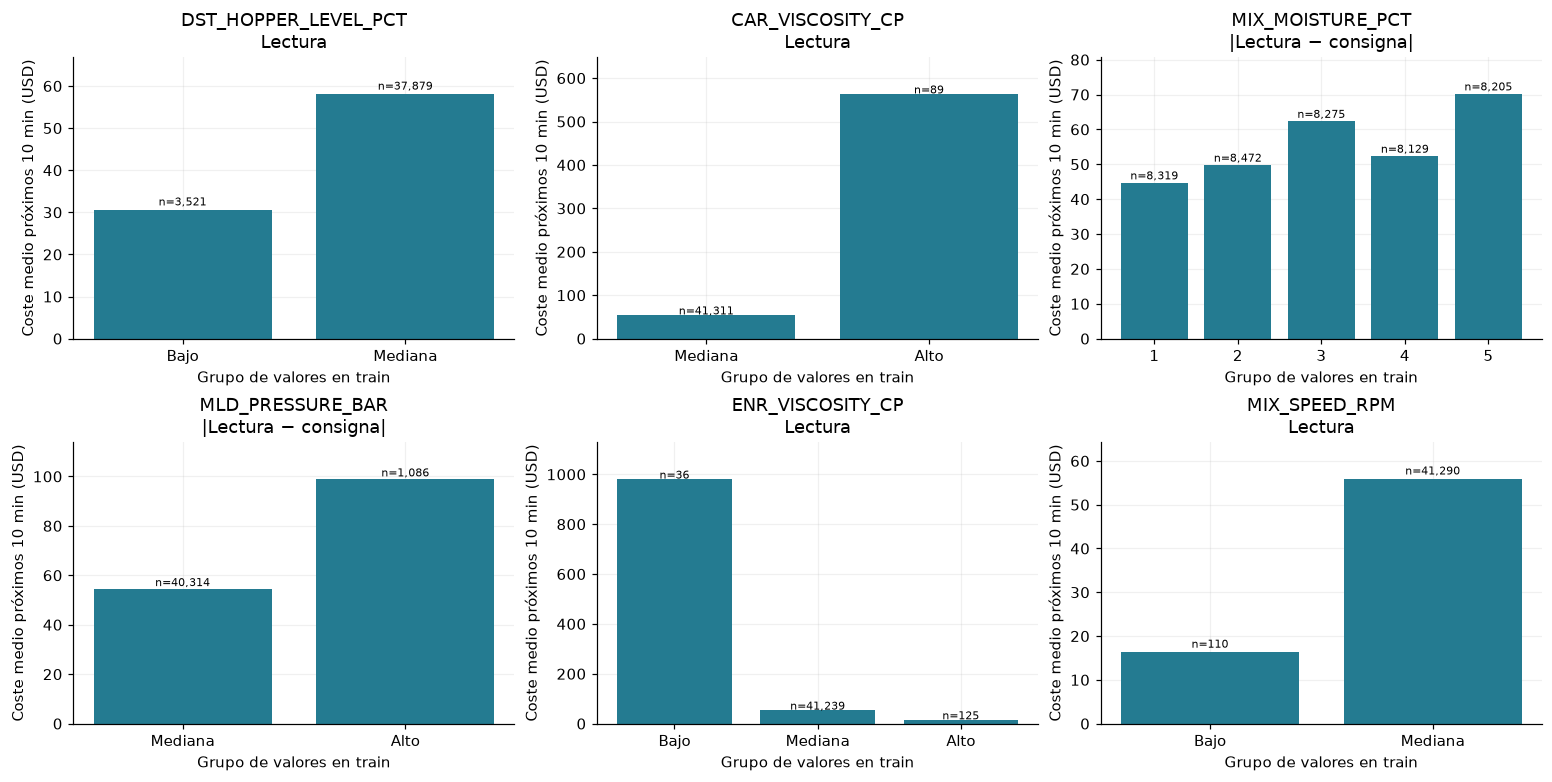

,grupo,coste_medio,n,sensor_min,sensor_max,parámetro,transformación
0,Bajo,30.63664,3521,0.000,99.125,DST_HOPPER_LEVEL_PCT,Lectura
1,Mediana,58.13089,37879,100.000,100.000,DST_HOPPER_LEVEL_PCT,Lectura
2,Mediana,54.69828,41311,8000.000,8000.000,CAR_VISCOSITY_CP,Lectura
3,Alto,563.72051,89,12500.000,12500.000,CAR_VISCOSITY_CP,Lectura
4,"(-0.001, 0.032]",44.67025,8319,0.000,0.032,MIX_MOISTURE_PCT,Desviación absoluta de consigna
5,"(0.032, 0.065]",49.74638,8472,0.033,0.065,MIX_MOISTURE_PCT,Desviación absoluta de consigna
6,"(0.065, 0.102]",62.31002,8275,0.066,0.102,MIX_MOISTURE_PCT,Desviación absoluta de consigna
7,"(0.102, 0.165]",52.31383,8129,0.103,0.165,MIX_MOISTURE_PCT,Desviación absoluta de consigna
8,"(0.165, 2.191]",70.18575,8205,0.166,2.191,MIX_MOISTURE_PCT,Desviación absoluta de consigna
9,Mediana,54.62850,40314,0.000,0.000,MLD_PRESSURE_BAR,Desviación absoluta de consigna


Estos grupos sirven para estudiar la forma de la asociación. No son importancias de un modelo ni estimaciones de ahorro. Algunos sensores comparten cambios de estado y aportan información redundante. El compañero de ML deberá contrastarlos con referencias simples basadas en hora/turno y en el historial reciente, y evaluar por episodios además de por minuto. El porcentaje de ventanas positivas ayuda a decidir si conviene predecir importe, exceso sobre lo habitual o una clase de riesgo alto. Se comparan lectura y desviación absoluta respecto a consigna para explorar efectos no monótonos. rho_dentro_turno correlaciona rangos calculados dentro de cada turno; controla ese contexto de forma descriptiva, pero no elimina otros factores comunes. Con muchos valores repetidos se usan grupos bajo/igual/alto respecto a la mediana sin separar artificialmente observaciones idénticas. Se informa el tamaño de cada grupo.

In [19]:
# Ranking exploratorio de sensores actuales frente a coste futuro: solo train y ventanas válidas.
candidate_rows=[]
setpoints_wide=telemetry.pivot(index='minute_ts',columns='parameter_code',values='value_setpoint').reindex(idx)
absolute_deviation=(telemetry_wide-setpoints_wide).abs()
for feature in telemetry_wide.columns:
    for transformation,x in [('Lectura',minute[feature]),('Desviación absoluta de consigna',absolute_deviation[feature])]:
        rho,n=rank_correlation(x,target_frame.future_scrap_cost_usd,train_mask)
        a=pd.DataFrame({'x':x,'y':target_frame.future_scrap_cost_usd,
                         'turno':minute.shift_code.astype(str)}).loc[train_mask].dropna()
        within=a.groupby('turno',observed=True)[['x','y']].rank(pct=True)
        within_rho=within.x.corr(within.y) if within.x.nunique()>1 and within.y.nunique()>1 else np.nan
        candidate_rows.append({'parámetro':feature,'transformación':transformation,
                               'rho_coste_futuro':rho,'rho_dentro_turno':within_rho,'ventanas_train':n,
                               'n_valores_train':x.loc[train_mask].nunique()})
candidate_signals=pd.DataFrame(candidate_rows).sort_values('rho_coste_futuro',key=lambda x:x.abs(),ascending=False)
candidate_signals=candidate_signals.merge(parameter[['parameter_code','machine_code','unit']],
    left_on='parámetro',right_on='parameter_code',how='left',validate='many_to_one').drop(columns='parameter_code')
show(candidate_signals,12)
chosen=candidate_signals.dropna(subset=['rho_coste_futuro']).drop_duplicates('parámetro').head(6)
fig,axs=plt.subplots(2,3,figsize=(14,7),layout='constrained')
candidate_groups=[]
for ax,(_,chosen_row) in zip(axs.flat,chosen.iterrows()):
    feature=chosen_row['parámetro']
    x=minute[feature] if chosen_row['transformación']=='Lectura' else absolute_deviation[feature]
    a=pd.DataFrame({'sensor':x.loc[train_mask],
                    'coste_futuro':target_frame.loc[train_mask,'future_scrap_cost_usd']})
    a['grupo']=pd.qcut(a.sensor,q=5,duplicates='drop')
    if a.grupo.nunique()<3:
        median=a.sensor.median()
        a['grupo']=pd.Categorical(np.select([a.sensor<median,a.sensor>median],['Bajo','Alto'],default='Mediana'),
                                  categories=['Bajo','Mediana','Alto'],ordered=True)
    g=a.groupby('grupo',observed=True).agg(coste_medio=('coste_futuro','mean'),n=('coste_futuro','size'),
                                          sensor_min=('sensor','min'),sensor_max=('sensor','max'))
    candidate_groups.append(g.reset_index().assign(parámetro=feature,transformación=chosen_row['transformación']))
    if len(g):
        ax.bar(range(len(g)),g.coste_medio,color=COLORS[1])
        labels=[str(v) for v in g.index] if g.index.dtype=='category' and all(isinstance(v,str) for v in g.index) else [str(i+1) for i in range(len(g))]
        ax.set_xticks(range(len(g)),labels)
        for i,row in enumerate(g.itertuples()):
            ax.text(i,row.coste_medio+1,f'n={row.n:,}',ha='center',fontsize=7)
    prefix='Lectura' if chosen_row['transformación']=='Lectura' else '|Lectura − consigna|'
    ax.set(title=f'{feature}\n{prefix}', xlabel='Grupo de valores en train',ylabel=f'Coste medio próximos {H} min (USD)')
    ax.margins(y=.15)
for ax in list(axs.flat)[len(chosen):]:ax.set_visible(False)
figure(fig,'06_sensores_coste_futuro_train')
export_table(candidate_signals,'senales_candidatas_train',index=False)
candidate_groups=pd.concat(candidate_groups,ignore_index=True)
show(candidate_groups,18)
export_table(candidate_groups,'grupos_sensores_train',index=False)
explain('Estos grupos sirven para estudiar la forma de la asociación. No son importancias de un '
        'modelo ni estimaciones de ahorro. Algunos sensores comparten cambios de estado y '
        'aportan información redundante. El compañero de ML deberá contrastarlos con referencias '
        'simples basadas en hora/turno y en el historial reciente, y evaluar por episodios además '
        'de por minuto. El porcentaje de ventanas positivas ayuda a decidir si conviene '
        'predecir importe, exceso sobre lo habitual o una clase de riesgo alto. '
        'Se comparan lectura y desviación absoluta respecto a consigna para explorar efectos '
        'no monótonos. rho_dentro_turno correlaciona rangos calculados dentro de cada turno; '
        'controla ese contexto de forma descriptiva, pero no elimina otros factores comunes. '
        'Con muchos valores repetidos se usan grupos bajo/igual/alto respecto a la mediana '
        'sin separar artificialmente observaciones idénticas. Se informa el tamaño de cada grupo.')


<a id="7-conclusiones-y-oportunidades"></a>

## 7. Conclusiones y oportunidades

### 7.1. Diagnóstico y decisiones para el equipo

Los siguientes resultados se calculan al ejecutar el notebook. Se mantienen separados el
coste observado, las asociaciones y las intervenciones que requieren validación.


In [20]:
normal_cost=float(minute.loc[minute.reference_window,'scrap_cost_usd'].sum())
normal_final_cost=float(minute.loc[minute.reference_window,'FIN_BAR_cost_usd'].sum())
height_counts=float(bar.height_oos.sum())
all_bar_pieces=float(bar.pieces.sum())
height_share_final=100*height_counts/minute.FIN_BAR_piece_count.sum()
base_sensitivity=sensitivity.loc[(sensitivity.antes_min==EVENT_BUFFER_BEFORE_MIN)&
                                (sensitivity['después_min']==EVENT_BUFFER_AFTER_MIN)].iloc[0]
explain(f"""### Hallazgos principales

1. **Referencia económica:** {total_scrap_usd:,.2f} USD de scrap total en {len(days)} días.
   {final_scrap_usd:,.2f} USD corresponden al punto final. No son cifras anuales.
2. **Altura final:** {height_counts:,.0f} conteos fuera de altura, un
   {100*height_counts/all_bar_pieces:.3f} % de las piezas medidas. Equivalen al
   {height_share_final:.2f} % del volumen de retirada final; no son categorías exclusivas de defectos.
3. **Concentración:** los cinco carriles prioritarios acumulan {edge_share:.2f} % de los
   conteos finales de altura y {edge_volume:.2f} % de las piezas. El patrón sigue presente
   fuera del entorno de incidencias: {base_sensitivity.porcentaje_altura_cinco_carriles:.2f} %
   de los conteos de altura de esa referencia se concentra en esos cinco carriles.
4. **Origen a investigar:** la comparación alineada de láseres y la descripción del HTML
   apuntan a la uniformidad de cobertura. Debe descartarse sesgo del sistema de medida.
5. **Episodios:** crema, caramelo, alimentación, corte y chocolate tienen mecanismos y
   retardos diferentes. Un único porcentaje de acierto no describe su utilidad por igual.
6. **Anticipación:** la presencia de scrap y el coste alto son objetivos distintos.
   En train, la presencia de scrap alcanza el {presence_train:.2f} % de las ventanas.
   La tabla de particiones y el ranking de señales permiten elegir un planteamiento sin
   usar resultados futuros como entradas ni entrenar un modelo dentro del EDA.
""")
opportunities=pd.DataFrame([
 {'oportunidad':'Uniformidad de cobertura por carril',
  'evidencia':'Perfil núcleo/barrita, concentración en bordes y narrativa del HTML',
  'acción_a_validar':'Comprobar calibración, distribución de cortina, cobertura inferior y aire',
  'implementación_posible':'Monitorizar perfil transversal y deriva con medidas ya disponibles',
  'métrica':'Tasa final por carril, dispersión entre carriles y coste FIN_BAR',
  'límite':'No hay controles ni sensores de cobertura por carril; no prometer ajuste automático'},
 {'oportunidad':'Anticipar episodios de alto scrap',
  'evidencia':'Contrastes de mecanismos y asociaciones temporales en train',
  'acción_a_validar':'Alerta con margen útil y revisión del proceso implicado',
  'implementación_posible':'Previsión de coste o riesgo futuro global y priorización de estaciones',
  'métrica':'Anticipación por episodio, falsas alarmas y coste neto evitado',
  'límite':'Etiquetas de máquina parciales; varias incidencias pueden solaparse'},
 {'oportunidad':'Reducir retiradas de galleta y guillotina',
  'evidencia':'Costes POST_CAM/GUI_CHUTE y señales de masa, alimentación y sincronización',
  'acción_a_validar':'Revisión de humedad, presión, alimentación o fase según el mecanismo',
  'implementación_posible':'Alertas diferenciadas por etapa y consulta de episodios similares',
  'métrica':'Coste y kg por punto, ajustados por exposición disponible',
  'límite':'Eventos de cámara no son piezas únicas; falta exposición completa de cada etapa'},
 {'oportunidad':'Evitar pérdidas de cargas de masa',
  'evidencia':'Retiradas MLD_DUMP y duración de incidencias de moldeado',
  'acción_a_validar':'Investigar episodios largos y su secuencia hasta el vertido',
  'implementación_posible':'Seguimiento del tiempo del episodio y apoyo a la respuesta',
  'métrica':'Cargas, kg y coste de masa retirada',
  'límite':'Pocos vertidos; no extrapolar fiabilidad desde numerosos minutos correlacionados'}])
show(opportunities,4)
export_table(opportunities,'oportunidades',index=False)


### Hallazgos principales

1. **Referencia económica:** 340,843.54 USD de scrap total en 65 días.
   296,001.73 USD corresponden al punto final. No son cifras anuales.
2. **Altura final:** 1,628,513 conteos fuera de altura, un
   1.416 % de las piezas medidas. Equivalen al
   96.29 % del volumen de retirada final; no son categorías exclusivas de defectos.
3. **Concentración:** los cinco carriles prioritarios acumulan 77.13 % de los
   conteos finales de altura y 15.49 % de las piezas. El patrón sigue presente
   fuera del entorno de incidencias: 96.67 %
   de los conteos de altura de esa referencia se concentra en esos cinco carriles.
4. **Origen a investigar:** la comparación alineada de láseres y la descripción del HTML
   apuntan a la uniformidad de cobertura. Debe descartarse sesgo del sistema de medida.
5. **Episodios:** crema, caramelo, alimentación, corte y chocolate tienen mecanismos y
   retardos diferentes. Un único porcentaje de acierto no describe su utilidad por igual.
6. **Anticipación:** la presencia de scrap y el coste alto son objetivos distintos.
   En train, la presencia de scrap alcanza el 96.37 % de las ventanas.
   La tabla de particiones y el ranking de señales permiten elegir un planteamiento sin
   usar resultados futuros como entradas ni entrenar un modelo dentro del EDA.


,oportunidad,evidencia,acción_a_validar,implementación_posible,métrica,límite
0,Uniformidad de cobertura por carril,"Perfil núcleo/barrita, concentración en bordes y narrativa del HTML","Comprobar calibración, distribución de cortina, cobertura inferior y aire",Monitorizar perfil transversal y deriva con medidas ya disponibles,"Tasa final por carril, dispersión entre carriles y coste FIN_BAR",No hay controles ni sensores de cobertura por carril; no prometer ajuste automático
1,Anticipar episodios de alto scrap,Contrastes de mecanismos y asociaciones temporales en train,Alerta con margen útil y revisión del proceso implicado,Previsión de coste o riesgo futuro global y priorización de estaciones,"Anticipación por episodio, falsas alarmas y coste neto evitado",Etiquetas de máquina parciales; varias incidencias pueden solaparse
2,Reducir retiradas de galleta y guillotina,"Costes POST_CAM/GUI_CHUTE y señales de masa, alimentación y sincronización","Revisión de humedad, presión, alimentación o fase según el mecanismo",Alertas diferenciadas por etapa y consulta de episodios similares,"Coste y kg por punto, ajustados por exposición disponible",Eventos de cámara no son piezas únicas; falta exposición completa de cada etapa
3,Evitar pérdidas de cargas de masa,Retiradas MLD_DUMP y duración de incidencias de moldeado,Investigar episodios largos y su secuencia hasta el vertido,Seguimiento del tiempo del episodio y apoyo a la respuesta,"Cargas, kg y coste de masa retirada",Pocos vertidos; no extrapolar fiabilidad desde numerosos minutos correlacionados


### 7.2. Cómo valorar una mejora sin inventar ahorro

Una alerta no reduce desperdicio por sí misma. El beneficio debe asociarse a una actuación,
su tiempo de respuesta y la cantidad que todavía pueda salvarse. No se propone retirar
barritas individuales ni recuperar costes que ya se han incurrido.

**Beneficio neto incremental = coste de scrap evitado por la actuación − coste de intervenir
− pérdidas inducidas por falsas alarmas o cambios de proceso.** Si se incorpora margen de
producción recuperada, debe calcularse sin duplicar costes ya incluidos en ese margen.

Para combinar dos actuaciones hay que identificar ventanas y material solapados. La base
de evaluación debe tener el mismo periodo y puntos de scrap que el numerador. Una simulación
histórica o una extrapolación no equivalen a ahorro demostrado.


In [21]:
# Sensibilidad ilustrativa sobre una base observada. Las eficacias son supuestos, no resultados.
scenario=pd.DataFrame({'eficacia_hipotética':[0,.05,.10,.20]})
scenario['base_FIN_BAR_referencia_usd']=normal_final_cost
scenario['coste_material_evitado_bruto_usd']=scenario['eficacia_hipotética']*normal_final_cost
scenario['costes_intervención_y_efectos_adversos']='Pendientes de medir; no se presupone cero'
show(scenario,4)
explain('La base anterior es el coste final observado fuera del entorno de incidencias, no todo '
        'el coste demostrablemente causado por la cortina. Las eficacias solo muestran una '
        'sensibilidad económica; no son ahorro previsto ni neto. No se anualiza ni se suma '
        'esta tabla a ningún resultado de modelos.')
export_table(scenario,'sensibilidad_economica_hipotetica',index=False)


,eficacia_hipotética,base_FIN_BAR_referencia_usd,coste_material_evitado_bruto_usd,costes_intervención_y_efectos_adversos
0,0.00,185856.80056,0.00000,Pendientes de medir; no se presupone cero
1,0.05,185856.80056,9292.84003,Pendientes de medir; no se presupone cero
2,0.10,185856.80056,18585.68006,Pendientes de medir; no se presupone cero
3,0.20,185856.80056,37171.36011,Pendientes de medir; no se presupone cero


La base anterior es el coste final observado fuera del entorno de incidencias, no todo el coste demostrablemente causado por la cortina. Las eficacias solo muestran una sensibilidad económica; no son ahorro previsto ni neto. No se anualiza ni se suma esta tabla a ningún resultado de modelos.

### 7.3. Entrega a modelado y siguientes comprobaciones

- **Unidad y decisión:** ventana futura de línea, con decisión al fin de t. Si cambia el
  punto de decisión, rehacer la disponibilidad de variables y los retardos relevantes.
- **Objetivos candidatos:** importe total o por punto en t+1…t+H, tasa final cuando hay
  exposición y clase de coste alto con umbral elegido en entrenamiento.
- **Entradas:** lecturas hasta t, desviaciones de consigna y contexto conocido. Los lags
  históricos pueden estudiarse después. Las mediciones finales de la ventana, el coste futuro, el fin de
  incidencia y el diagnóstico retrospectivo no son predictores tempranos.
- **Evaluación:** bloques temporales con historia y horizonte completos dentro del bloque.
  Agrupar alertas repetidas y episodios al valorar beneficios. Medir precisión/recobrado,
  cobertura de decisión y anticipación por tipo de problema y coste. Comparar con reglas
  simples, patrones por turno y persistencia reciente.
- **Estación sospechosa:** tratar los eventos como supervisión parcial, contemplar varios
  candidatos y permitir abstención. Explicar una predicción no demuestra una causa física.
- **Interfaz y agente:** mostrar señal, estación candidata, evidencia, margen de actuación
  y recomendación documentada. Diferenciar coste observado de ahorro hipotético.
- **Datos adicionales prioritarios:** ajustes por carril, calibración de láseres, acciones
  de operarios con fecha/hora, respuesta de calidad posterior, exposición por etapa y
  vínculo de producto entre estaciones. Permitirían evaluar intervenciones y trazabilidad.

### Límites que deben acompañar a las conclusiones

El conjunto simulado tiene una única referencia de producto, ventanas muy correlacionadas,
rangos de catálogo y mecanismos definidos por el caso. La dispersión registrada de los
láseres es constante por etapa. Faltan identificadores individuales, causas exclusivas,
latencias reales de registro y un historial de intervenciones. Los límites de especificación
del núcleo y de la barrita son diferentes; sus rechazos no se restan para medir defectos nuevos.
La calidad final después del enfriador también puede contener pérdidas que el láser anterior
no detecta. Los puntos de recogida disponibles determinan qué scrap se puede valorar aquí.


In [22]:
# Verificaciones finales y exportación de resultados de entrega.
check('Las tablas por punto concilian con coste original',
      np.isclose(point_summary.coste_usd.sum(),scrap.cost_usd.sum()),fatal=True)
check('La tabla diaria conserva el coste',np.isclose(daily.scrap_cost_usd.sum(),total_scrap_usd),fatal=True)
check('La tabla mensual conserva el coste',np.isclose(monthly.scrap_cost_usd.sum(),total_scrap_usd),fatal=True)
check('Las particiones tienen orden temporal',
      split_summary.loc['train','hasta']<split_summary.loc['validation','desde']
      <split_summary.loc['test','desde'],fatal=True)
check('Todas las fuentes conservan su SHA-256',
      all(fingerprint(DATA/f'{name}.csv')==row.sha256 for name,row in inventory.iterrows()),fatal=True)
audit=pd.DataFrame(checks)
display(audit)
if (~audit.cumple).any():
    display(audit.loc[~audit.cumple])
export_table(audit,'comprobaciones',index=False)
export_table(reconciliation_summary,'conciliacion_conteos',index=False)
export_table(quality,'calidad_claves')
export_table(missing,'valores_ausentes',index=False)
summary={
 'periodo':{'desde':str(idx.min()),'hasta':str(idx.max()),'dias':len(days),'minutos':len(idx)},
 'versiones':versions,
 'coste_total_scrap_usd':total_scrap_usd,'coste_FIN_BAR_usd':final_scrap_usd,
 'coste_por_punto':point_summary.coste_usd.to_dict(),
 'altura_final_oos':int(height_counts),'piezas_medidas_final':int(all_bar_pieces),
 'carriles_prioritarios':priority_lanes,'porcentaje_altura_cinco_carriles':float(edge_share),
 'porcentaje_exposicion_cinco_carriles':float(edge_volume),
 'coste_referencia_sin_incidencias_usd':normal_cost,
 'buffer_incidencias':{'antes_min':EVENT_BUFFER_BEFORE_MIN,'despues_min':EVENT_BUFFER_AFTER_MIN},
 'horizonte_futuro_min':H,'umbral_coste_alto_train_usd':high_cost_threshold,
 'comprobaciones':{'total':len(audit),'incumplidas':int((~audit.cumple).sum())},
 'advertencia':'EDA descriptivo. No se ha entrenado un modelo ni demostrado ahorro causal.'}
if EXPORT_RESULTS:
    (OUT/'resumen_eda.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
    print('Resultados guardados en analysis/eda_scrap/. Las figuras también están integradas en el notebook.')
explain(f'**Fin del análisis:** {len(audit)} comprobaciones ejecutadas. '
        f'{int((~audit.cumple).sum())} incumplimientos; revisar cualquier fila que no cumpla. '
        'Los desacuerdos entre fuentes de conteo se documentan en la sección 2 y no se reparan '
        'inventando trazabilidad. Los archivos originales se han verificado por hash.')


,comprobación,cumple,detalle
0,Están los nueve CSV esperados,True,
1,Clave única y completa: fct_laser_bar_minute,True,"duplicados=0, claves nulas=0"
2,Clave única y completa: fct_laser_core_minute,True,"duplicados=0, claves nulas=0"
3,Clave única y completa: fct_oee_minute,True,"duplicados=0, claves nulas=0"
4,Clave única y completa: fct_problem_event,True,"duplicados=0, claves nulas=0"
...,...,...,...
42,Las tablas por punto concilian con coste original,True,
43,La tabla diaria conserva el coste,True,
44,La tabla mensual conserva el coste,True,
45,Las particiones tienen orden temporal,True,


,comprobación,cumple,detalle
31,Duración declarada coincide con fin menos inicio,False,7 eventos con discrepancia; se conservan ambos campos


Resultados guardados en analysis/eda_scrap/. Las figuras también están integradas en el notebook.


**Fin del análisis:** 47 comprobaciones ejecutadas. 1 incumplimientos; revisar cualquier fila que no cumpla. Los desacuerdos entre fuentes de conteo se documentan en la sección 2 y no se reparan inventando trazabilidad. Los archivos originales se han verificado por hash.